In [ ]:
import math
import time
from datetime import datetime
import ee

# -------------------------------------------------------------------------
# 1. Initialize Earth Engine
# -------------------------------------------------------------------------
try:
    ee.Initialize(project='landsat89-509617')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='landsat89-509617')

# -------------------------------------------------------------------------
# 2. Define the 5 Bioclimatic Archetypes & 4 Indian Climatological Seasons
# -------------------------------------------------------------------------
city_archetypes = {
    # 1. Composite / Hot-Dry Central Plains
    "nagpur_composite": ee.Geometry.BBox(78.95, 21.05, 79.25, 21.25),
    # 2. Warm & Humid / Coastal
    "mumbai_coastal": ee.Geometry.BBox(72.75, 18.90, 73.05, 19.25),
    # 3. Tropical Wet & Dry / Semi-Arid Deccan Plateau
    "hyderabad_plateau": ee.Geometry.BBox(78.30, 17.25, 78.60, 17.55),
    # 4. Temperate / Elevated Highland Canopy
    "bengaluru_highland": ee.Geometry.BBox(77.45, 12.85, 77.75, 13.15),
    # 5. Cold / Montane Sub-Himalayan Valley
    "dehradun_montane": ee.Geometry.BBox(77.90, 30.20, 78.20, 30.45)
}

# 4 Standard Climatological Windows (Using 2023 for complete Tier-1 coverage)
seasons = {
    "summer": {
        "start": "2023-04-01",
        "end": "2023-06-15",
        "cloud_thresh": 30
    },
    "monsoon": {
        "start": "2023-07-01",
        "end": "2023-09-15",
        "cloud_thresh": 65  # Relaxed cloud filter to acquire cloud-free gaps between showers
    },
    "post_monsoon": {
        "start": "2023-10-01",
        "end": "2023-11-30",
        "cloud_thresh": 30
    },
    "winter": {
        "start": "2023-12-15",
        "end": "2024-02-15",
        "cloud_thresh": 30
    }
}

# -------------------------------------------------------------------------
# 3. Helper: Compute Cyclical DOY Constants for Composite Window Midpoint
# -------------------------------------------------------------------------
def compute_seasonal_doy_constants(start_str, end_str):
    d1 = datetime.strptime(start_str, "%Y-%m-%d")
    d2 = datetime.strptime(end_str, "%Y-%m-%d")
    midpoint_date = d1 + (d2 - d1) / 2
    doy = midpoint_date.timetuple().tm_yday

    sin_val = math.sin(2.0 * math.pi * doy / 365.25)
    cos_val = math.cos(2.0 * math.pi * doy / 365.25)
    return float(sin_val), float(cos_val)

# -------------------------------------------------------------------------
# 4. Cloud Masking & Scaling for Landsat 8/9 Level-2 (Collection 2)
# -------------------------------------------------------------------------
def prep_landsat(image):
    qa = image.select('QA_PIXEL')
    cloud_shadow_mask = qa.bitwiseAnd(1 << 4).eq(0)
    clouds_mask = qa.bitwiseAnd(1 << 3).eq(0)
    mask = cloud_shadow_mask.And(clouds_mask)

    # Scale Optical Reflectance
    optical_bands = image.select(['SR_B3', 'SR_B4', 'SR_B5', 'SR_B6']) \
        .multiply(0.0000275).add(-0.2) \
        .rename(['Green', 'Red', 'NIR', 'SWIR1'])

    # Scale Thermal ST_B10 to Celsius
    lst_celsius = image.select('ST_B10') \
        .multiply(0.00341802).add(149.0).subtract(273.15) \
        .rename('LST')

    return image.addBands(optical_bands, overwrite=True) \
                .addBands(lst_celsius, overwrite=True) \
                .updateMask(mask)

# -------------------------------------------------------------------------
# 5. Pipeline to Generate 7-Band Seasonal City Stack
# -------------------------------------------------------------------------
def generate_seasonal_stack(aoi, season_cfg):
    start_d = season_cfg["start"]
    end_d = season_cfg["end"]
    cloud_max = season_cfg["cloud_thresh"]

    # Combine Landsat 8 and 9 collections
    landsat_col = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2') \
        .merge(ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')) \
        .filterBounds(aoi) \
        .filterDate(start_d, end_d) \
        .filter(ee.Filter.lt('CLOUD_COVER', cloud_max)) \
        .map(prep_landsat)

    composite = landsat_col.median().clip(aoi)

    # Spectral Indices
    ndvi = composite.normalizedDifference(['NIR', 'Red']).rename('NDVI')
    ndbi = composite.normalizedDifference(['SWIR1', 'NIR']).rename('NDBI')
    mndwi = composite.normalizedDifference(['Green', 'SWIR1']).rename('MNDWI')

    # Topography
    elevation = ee.Image('USGS/SRTMGL1_003').clip(aoi).select('elevation').rename('Elevation')

    # Temporal cyclical features
    sin_val, cos_val = compute_seasonal_doy_constants(start_d, end_d)
    doy_sin_img = ee.Image.constant(sin_val).toFloat().rename('doy_sin').clip(aoi)
    doy_cos_img = ee.Image.constant(cos_val).toFloat().rename('doy_cos').clip(aoi)

    # 7-Band Stack
    stack = composite.select('LST') \
        .addBands(ndvi) \
        .addBands(ndbi) \
        .addBands(mndwi) \
        .addBands(elevation) \
        .addBands(doy_sin_img) \
        .addBands(doy_cos_img) \
        .toFloat()

    return stack

# -------------------------------------------------------------------------
# 6. Launch All 20 Tasks to Google Drive
# -------------------------------------------------------------------------
folder_name = 'EarthEngine_Exports'
tasks = {}

print("=== Launching 20 Multi-Seasonal Archetype Export Tasks ===")
task_count = 0

for city_key, aoi in city_archetypes.items():
    for season_key, season_cfg in seasons.items():
        task_count += 1
        export_prefix = f"uhi_features_{city_key}_{season_key}_30m"
        stack = generate_seasonal_stack(aoi, season_cfg)

        task = ee.batch.Export.image.toDrive(
            image=stack,
            description=f"Export_{city_key}_{season_key}",
            folder=folder_name,
            fileNamePrefix=export_prefix,
            scale=30,
            region=aoi,
            crs='EPSG:4326',
            maxPixels=1e9
        )
        task.start()
        tasks[export_prefix] = task
        print(f"[{task_count:02d}/20] Started Export: {export_prefix} (ID: {task.id})")

# -------------------------------------------------------------------------
# 7. Asynchronous Multi-Task Monitor
# -------------------------------------------------------------------------
print(f"\nAll 20 export tasks submitted to Drive folder: '{folder_name}'.")
print("Monitoring progress every 40 seconds (Ctrl+C to stop monitoring; tasks run server-side)...\n")

pending = set(tasks.keys())
while pending:
    time.sleep(40)
    for export_id in list(pending):
        task = tasks[export_id]
        status = task.status()
        state = status.get('state')

        if state in ['COMPLETED', 'FAILED', 'CANCELLED']:
            print(f"-> Task [{export_id}] completed with state: {state}")
            if state != 'COMPLETED':
                print(f"   Diagnostic: {status.get('error_message')}")
            pending.remove(export_id)
        else:
            print(f"   [{export_id}] State: {state}")

print("\nAll 20 seasonal archetype rasters processed!")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


=== Launching 20 Multi-Seasonal Archetype Export Tasks ===
[01/20] Started Export: uhi_features_nagpur_composite_summer_30m (ID: IUL7P2AVSEEGHJ4SO2Z34EVW)
[02/20] Started Export: uhi_features_nagpur_composite_monsoon_30m (ID: DBVVOIRBNYO4OHNV4MSFCEMV)
[03/20] Started Export: uhi_features_nagpur_composite_post_monsoon_30m (ID: D4CNIZU56HJLZ2XCPISGPJ4B)
[04/20] Started Export: uhi_features_nagpur_composite_winter_30m (ID: ZPYFHZVE37P6YKZ2E72DFNSW)
[05/20] Started Export: uhi_features_mumbai_coastal_summer_30m (ID: BTYWUN2OFI4ETWCPAOUT2NI3)
[06/20] Started Export: uhi_features_mumbai_coastal_monsoon_30m (ID: OITSOD5ATMURR4Z2UE7K3PST)
[07/20] Started Export: uhi_features_mumbai_coastal_post_monsoon_30m (ID: IDFA3NLHQHFML7CDDZXHDQTI)
[08/20] Started Export: uhi_features_mumbai_coastal_winter_30m (ID: 2O5FAFSULUW4TCDHC6VSIXUZ)
[09/20] Started Export: uhi_features_hyderabad_plateau_summer_30m (ID: YPOKDLVVXUFS3GHM6QG4QCAH)
[10/20] Started Export: uhi_features_hyderabad_plateau_monsoon_30m (ID

In [ ]:
import math
import ee

# =========================================================================
# 1. INITIALIZE GOOGLE EARTH ENGINE
# =========================================================================
try:
    ee.Initialize(project='landsat89-509617')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='landsat89-509617')


# =========================================================================
# 2. CITY AOIs
# =========================================================================
city_archetypes = {

    "nagpur_composite":
        ee.Geometry.BBox(
            78.95, 21.05,
            79.25, 21.25
        ),

    "mumbai_coastal":
        ee.Geometry.BBox(
            72.75, 18.90,
            73.05, 19.25
        ),

    "hyderabad_plateau":
        ee.Geometry.BBox(
            78.30, 17.25,
            78.60, 17.55
        ),

    "bengaluru_highland":
        ee.Geometry.BBox(
            77.45, 12.85,
            77.75, 13.15
        ),

    "dehradun_montane":
        ee.Geometry.BBox(
            77.90, 30.20,
            78.20, 30.45
        )
}


# =========================================================================
# 3. SEASONAL WINDOWS
# =========================================================================
# Multi-year seasonal envelope: 2022-2024
#
# Summer       : Apr 1  - Jun 15
# Monsoon      : Jul 1  - Sep 15
# Post-monsoon : Oct 1  - Nov 30
# Winter       : Dec 15 - Feb 15 (cross-year)
# =========================================================================

seasonal_windows = {

    "summer": {
        "start_doy": 91,
        "end_doy": 166,
        "rep_doy": 128
    },

    "monsoon": {
        "start_doy": 182,
        "end_doy": 258,
        "rep_doy": 220
    },

    "post_monsoon": {
        "start_doy": 274,
        "end_doy": 334,
        "rep_doy": 304
    },

    "winter": {
        "start_doy": 349,
        "end_doy": 46,
        "rep_doy": 15
    }
}


YEARS = [2022, 2023, 2024]


# =========================================================================
# 4. LANDSAT 8/9 PREPROCESSING
# =========================================================================
def prepare_landsat(image):
    """
    Preprocess Landsat Collection 2 Level-2 imagery.

    Produces:
        Green
        Red
        NIR
        SWIR1
        LST
        Quality_Flag

    Quality_Flag:
        1 = clear + valid thermal observation
        0 = cloud/shadow/snow/invalid thermal observation
    """

    # ---------------------------------------------------------------------
    # QA_PIXEL
    # ---------------------------------------------------------------------
    qa = image.select('QA_PIXEL')

    # Landsat Collection 2 QA_PIXEL bits
    dilated_cloud = qa.bitwiseAnd(1 << 1).neq(0)
    cloud         = qa.bitwiseAnd(1 << 3).neq(0)
    cloud_shadow  = qa.bitwiseAnd(1 << 4).neq(0)
    snow          = qa.bitwiseAnd(1 << 5).neq(0)

    # Clear pixel = none of the unwanted conditions
    clear_qa = (
        dilated_cloud
        .Or(cloud)
        .Or(cloud_shadow)
        .Or(snow)
        .Not()
    )

    # ---------------------------------------------------------------------
    # Optical Surface Reflectance
    # ---------------------------------------------------------------------
    optical = (
        image
        .select([
            'SR_B3',
            'SR_B4',
            'SR_B5',
            'SR_B6'
        ])
        .multiply(0.0000275)
        .add(-0.2)
        .rename([
            'Green',
            'Red',
            'NIR',
            'SWIR1'
        ])
    )

    # ---------------------------------------------------------------------
    # Thermal Surface Temperature
    # ---------------------------------------------------------------------
    lst = (
        image
        .select('ST_B10')
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename('LST')
    )

    # ---------------------------------------------------------------------
    # Thermal validity
    # ---------------------------------------------------------------------
    thermal_valid = image.select('ST_B10').mask()

    # Final observation validity:
    # clear QA + valid thermal measurement
    valid = clear_qa.And(thermal_valid)

    # ---------------------------------------------------------------------
    # Apply SAME mask to optical and thermal data
    # ---------------------------------------------------------------------
    optical_masked = optical.updateMask(valid)
    lst_masked = lst.updateMask(valid)

    # ---------------------------------------------------------------------
    # Quality flag
    # ---------------------------------------------------------------------
    quality_flag = (
        valid
        .toFloat()
        .rename('Quality_Flag')
    )

    # ---------------------------------------------------------------------
    # Return processed image
    # ---------------------------------------------------------------------
    return (
        image
        .addBands(optical_masked, overwrite=True)
        .addBands(lst_masked, overwrite=True)
        .addBands(quality_flag, overwrite=True)
    )


# =========================================================================
# 5. BUILD SEASONAL LANDSAT COLLECTION
# =========================================================================
def build_collection(aoi, season_key, season_cfg):

    # Landsat 8
    l8 = (
        ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
        .filterBounds(aoi)
        .filter(
            ee.Filter.calendarRange(
                YEARS[0],
                YEARS[-1],
                'year'
            )
        )
    )

    # Landsat 9
    l9 = (
        ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
        .filterBounds(aoi)
        .filter(
            ee.Filter.calendarRange(
                YEARS[0],
                YEARS[-1],
                'year'
            )
        )
    )

    # Merge Landsat 8 + 9
    collection = l8.merge(l9)

    # ---------------------------------------------------------------------
    # Seasonal filtering
    # ---------------------------------------------------------------------
    if season_key == "winter":

        # December 15 - December 31
        december_filter = ee.Filter.calendarRange(
            season_cfg["start_doy"],
            366,
            'day_of_year'
        )

        # January 1 - February 15
        january_february_filter = ee.Filter.calendarRange(
            1,
            season_cfg["end_doy"],
            'day_of_year'
        )

        collection = collection.filter(
            ee.Filter.Or(
                december_filter,
                january_february_filter
            )
        )

    else:

        collection = collection.filter(
            ee.Filter.calendarRange(
                season_cfg["start_doy"],
                season_cfg["end_doy"],
                'day_of_year'
            )
        )

    return collection


# =========================================================================
# 6. MULTI-YEAR SEASONAL COMPOSITE
# =========================================================================
def generate_multiyear_stack(
    aoi,
    season_key,
    season_cfg
):

    # ---------------------------------------------------------------------
    # Build seasonal Landsat collection
    # ---------------------------------------------------------------------
    raw_collection = build_collection(
        aoi,
        season_key,
        season_cfg
    )

    # ---------------------------------------------------------------------
    # Apply preprocessing
    # ---------------------------------------------------------------------
    processed_collection = (
        raw_collection
        .map(prepare_landsat)
    )

    # ---------------------------------------------------------------------
    # Diagnostic count
    # ---------------------------------------------------------------------
    image_count = processed_collection.size()

    print(
        f"    {season_key}: "
        f"{image_count.getInfo()} Landsat images"
    )

    # ---------------------------------------------------------------------
    # Select quality observations
    # ---------------------------------------------------------------------
    quality_collection = (
        processed_collection
        .select('Quality_Flag')
    )

    # ---------------------------------------------------------------------
    # VALID OBSERVATION COUNT
    #
    # Sum of Quality_Flag:
    # 1 + 1 + 0 + 1 = 3 valid observations
    # ---------------------------------------------------------------------
    valid_observation_count = (
        quality_collection
        .sum()
        .rename('Valid_Observation_Count')
        .clip(aoi)
    )

    # ---------------------------------------------------------------------
    # TOTAL OBSERVATION COUNT
    # ---------------------------------------------------------------------
    observation_count = (
        quality_collection
        .count()
        .rename('Observation_Count')
        .clip(aoi)
    )

    # ---------------------------------------------------------------------
    # QUALITY SCORE
    #
    # Quality_Score =
    # valid observations / available observations
    # ---------------------------------------------------------------------
    quality_score = (
        valid_observation_count
        .divide(
            observation_count.max(1)
        )
        .rename('Quality_Score')
        .clip(aoi)
    )

    # ---------------------------------------------------------------------
    # CLEAN MULTI-YEAR MEDIAN COMPOSITE
    # ---------------------------------------------------------------------
    clean_composite = (
        processed_collection
        .select([
            'LST',
            'Green',
            'Red',
            'NIR',
            'SWIR1'
        ])
        .median()
        .clip(aoi)
    )

    # ---------------------------------------------------------------------
    # SPECTRAL INDICES
    # ---------------------------------------------------------------------

    # NDVI
    ndvi = (
        clean_composite
        .normalizedDifference([
            'NIR',
            'Red'
        ])
        .rename('NDVI')
    )

    # NDBI
    ndbi = (
        clean_composite
        .normalizedDifference([
            'SWIR1',
            'NIR'
        ])
        .rename('NDBI')
    )

    # MNDWI
    mndwi = (
        clean_composite
        .normalizedDifference([
            'Green',
            'SWIR1'
        ])
        .rename('MNDWI')
    )

    # ---------------------------------------------------------------------
    # TOPOGRAPHY
    # ---------------------------------------------------------------------
    srtm = (
        ee.Image('USGS/SRTMGL1_003')
        .select('elevation')
        .clip(aoi)
    )

    elevation = srtm.rename('Elevation')

    # ---------------------------------------------------------------------
    # CYCLICAL TEMPORAL FEATURES
    # ---------------------------------------------------------------------
    rep_doy = season_cfg["rep_doy"]

    doy_sin_value = math.sin(
        2.0 * math.pi * rep_doy / 365.25
    )

    doy_cos_value = math.cos(
        2.0 * math.pi * rep_doy / 365.25
    )

    doy_sin = (
        ee.Image.constant(doy_sin_value)
        .toFloat()
        .rename('doy_sin')
        .clip(aoi)
    )

    doy_cos = (
        ee.Image.constant(doy_cos_value)
        .toFloat()
        .rename('doy_cos')
        .clip(aoi)
    )

    # ---------------------------------------------------------------------
    # FINAL STACK
    #
    # 10 bands:
    #
    # 1  LST
    # 2  NDVI
    # 3  NDBI
    # 4  MNDWI
    # 5  Elevation
    # 6  doy_sin
    # 7  doy_cos
    # 8  Quality_Score
    # 9  Valid_Observation_Count
    # 10 Observation_Count
    # ---------------------------------------------------------------------
    stack = (
        clean_composite
        .select('LST')

        .addBands(ndvi)
        .addBands(ndbi)
        .addBands(mndwi)

        .addBands(elevation)

        .addBands(doy_sin)
        .addBands(doy_cos)

        .addBands(quality_score)

        .addBands(
            valid_observation_count
        )

        .addBands(
            observation_count
        )

        .toFloat()
    )

    return stack


# =========================================================================
# 7. DIAGNOSTIC TEST — RUN BEFORE 20 EXPORTS
# =========================================================================
print("\n" + "=" * 80)
print("DIAGNOSTIC TEST")
print("=" * 80)

test_city = "mumbai_coastal"
test_season = "summer"

test_stack = generate_multiyear_stack(
    city_archetypes[test_city],
    test_season,
    seasonal_windows[test_season]
)

test_stats = test_stack.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=city_archetypes[test_city],
    scale=30,
    maxPixels=1e9
)

print("\nMumbai Summer mean values:")
print(test_stats.getInfo())


# =========================================================================
# 8. BATCH EXPORT
# =========================================================================
#
# IMPORTANT:
# The diagnostic above should produce real numeric values BEFORE running
# all 20 exports.
# =========================================================================

RUN_EXPORTS = True

folder_name = 'EarthEngine_Exports_MultiYear'

tasks = {}

if RUN_EXPORTS:

    print("\n" + "=" * 80)
    print("STARTING 20 MULTI-YEAR SEASONAL EXPORTS")
    print("=" * 80)

    for city_key, aoi in city_archetypes.items():

        print(f"\nProcessing city: {city_key}")

        for season_key, season_cfg in seasonal_windows.items():

            print(f"  Processing season: {season_key}")

            prefix = (
                f"uhi_features_"
                f"{city_key}_"
                f"{season_key}_"
                f"multiyear_30m"
            )

            # Generate stack
            stack = generate_multiyear_stack(
                aoi,
                season_key,
                season_cfg
            )

            # Export
            task = ee.batch.Export.image.toDrive(
                image=stack,

                description=(
                    f"Export_"
                    f"{city_key}_"
                    f"{season_key}"
                ),

                folder=folder_name,

                fileNamePrefix=prefix,

                scale=30,

                region=aoi,

                crs='EPSG:4326',

                maxPixels=1e9
            )

            task.start()

            tasks[prefix] = task

            print(
                f"    ✓ Submitted: {prefix}"
            )

            print(
                f"      Task ID: {task.id}"
            )


    print("\n" + "=" * 80)
    print("ALL EXPORTS QUEUED")
    print("=" * 80)

    print(
        f"Google Drive folder: {folder_name}"
    )

    print(
        f"Total tasks submitted: {len(tasks)}"
    )

else:

    print(
        "\nRUN_EXPORTS=False"
        "\nOnly the Mumbai Summer diagnostic was executed."
        "\nSet RUN_EXPORTS=True after verifying the diagnostic."
    )



DIAGNOSTIC TEST
    summer: 76 Landsat images

Mumbai Summer mean values:
{'Elevation': 20.847770359107834, 'LST': 38.050140450139935, 'MNDWI': -0.10418793251411504, 'NDBI': -0.05464152820822177, 'NDVI': 0.16023662213506693, 'Observation_Count': 27.20355926972059, 'Quality_Score': 0.7117210117238835, 'Valid_Observation_Count': 19.365031218445107, 'doy_cos': -0.5900444984436035, 'doy_sin': 0.8073707222938538}

STARTING 20 MULTI-YEAR SEASONAL EXPORTS

Processing city: nagpur_composite
  Processing season: summer
    summer: 56 Landsat images
    ✓ Submitted: uhi_features_nagpur_composite_summer_multiyear_30m
      Task ID: GI7WEVONFG6BKEJXXDQDAVYC
  Processing season: monsoon
    monsoon: 15 Landsat images
    ✓ Submitted: uhi_features_nagpur_composite_monsoon_multiyear_30m
      Task ID: 252XPX62W2ATGQDVBBMOPHXZ
  Processing season: post_monsoon
    post_monsoon: 41 Landsat images
    ✓ Submitted: uhi_features_nagpur_composite_post_monsoon_multiyear_30m
      Task ID: FSFLH53UFDNRNM2AO

In [ ]:
all_dataframes = []

for file in files:

    print("\nProcessing:")
    print(os.path.basename(file))

    with rasterio.open(file) as src:

        # ------------------------------------------------
        # Read the 10 exported bands
        # ------------------------------------------------

        LST = src.read(1).astype(float)

        NDVI = src.read(2).astype(float)

        NDBI = src.read(3).astype(float)

        MNDWI = src.read(4).astype(float)

        Elevation = src.read(5).astype(float)

        doy_sin = src.read(6).astype(float)

        doy_cos = src.read(7).astype(float)

        Quality_Score = src.read(8).astype(float)

        Valid_Observation_Count = src.read(9).astype(float)

        Observation_Count = src.read(10).astype(float)


        # ------------------------------------------------
        # Replace nodata with NaN
        # ------------------------------------------------

        if src.nodata is not None:

            nodata = src.nodata

            LST[LST == nodata] = np.nan
            NDVI[NDVI == nodata] = np.nan
            NDBI[NDBI == nodata] = np.nan
            MNDWI[MNDWI == nodata] = np.nan
            Elevation[Elevation == nodata] = np.nan
            doy_sin[doy_sin == nodata] = np.nan
            doy_cos[doy_cos == nodata] = np.nan
            Quality_Score[Quality_Score == nodata] = np.nan
            Valid_Observation_Count[
                Valid_Observation_Count == nodata
            ] = np.nan
            Observation_Count[
                Observation_Count == nodata
            ] = np.nan


        # ------------------------------------------------
        # Neighborhood features
        # ------------------------------------------------

        NDVI_mean_3x3 = mean_filter(
            NDVI,
            size=3
        )

        NDBI_mean_5x5 = mean_filter(
            NDBI,
            size=5
        )

        NDBI_std_3x3 = std_filter(
            NDBI,
            size=3
        )

        NDVI_std_3x3 = std_filter(
            NDVI,
            size=3
        )

        MNDWI_mean_3x3 = mean_filter(
            MNDWI,
            size=3
        )


        # ------------------------------------------------
        # Flatten arrays
        # ------------------------------------------------

        LST_flat = LST.ravel()

        NDVI_flat = NDVI.ravel()

        NDBI_flat = NDBI.ravel()

        MNDWI_flat = MNDWI.ravel()

        Elevation_flat = Elevation.ravel()

        NDVI_mean_3x3_flat = NDVI_mean_3x3.ravel()

        NDBI_mean_5x5_flat = NDBI_mean_5x5.ravel()

        NDBI_std_3x3_flat = NDBI_std_3x3.ravel()

        NDVI_std_3x3_flat = NDVI_std_3x3.ravel()

        MNDWI_mean_3x3_flat = MNDWI_mean_3x3.ravel()

        doy_sin_flat = doy_sin.ravel()

        doy_cos_flat = doy_cos.ravel()


        # ------------------------------------------------
        # Create valid-pixel mask
        # ------------------------------------------------

        valid_mask = (

            np.isfinite(NDVI_flat) &

            np.isfinite(NDBI_flat) &

            np.isfinite(MNDWI_flat) &

            np.isfinite(Elevation_flat) &

            np.isfinite(NDVI_mean_3x3_flat) &

            np.isfinite(NDBI_mean_5x5_flat) &

            np.isfinite(NDBI_std_3x3_flat) &

            np.isfinite(NDVI_std_3x3_flat) &

            np.isfinite(MNDWI_mean_3x3_flat) &

            np.isfinite(doy_sin_flat) &

            np.isfinite(doy_cos_flat)
        )


        # ------------------------------------------------
        # Create DataFrame
        # ------------------------------------------------

        df_city = pd.DataFrame({

            "NDVI":
                NDVI_flat[valid_mask],

            "NDBI":
                NDBI_flat[valid_mask],

            "MNDWI":
                MNDWI_flat[valid_mask],

            "Elevation":
                Elevation_flat[valid_mask],

            "NDVI_mean_3x3":
                NDVI_mean_3x3_flat[valid_mask],

            "NDBI_mean_5x5":
                NDBI_mean_5x5_flat[valid_mask],

            "NDBI_std_3x3":
                NDBI_std_3x3_flat[valid_mask],

            "NDVI_std_3x3":
                NDVI_std_3x3_flat[valid_mask],

            "MNDWI_mean_3x3":
                MNDWI_mean_3x3_flat[valid_mask],

            "doy_sin":
                doy_sin_flat[valid_mask],

            "doy_cos":
                doy_cos_flat[valid_mask],

            # Keep LST separately for later UHI analysis
            "LST":
                LST_flat[valid_mask]
        })


        # ------------------------------------------------
        # Extract city and season from filename
        # ------------------------------------------------

        filename = os.path.basename(file)

        df_city["source_file"] = filename

        if "nagpur_composite" in filename:
            df_city["city"] = "Nagpur"

        elif "mumbai_coastal" in filename:
            df_city["city"] = "Mumbai"

        elif "hyderabad_plateau" in filename:
            df_city["city"] = "Hyderabad"

        elif "bengaluru_highland" in filename:
            df_city["city"] = "Bengaluru"

        elif "dehradun_montane" in filename:
            df_city["city"] = "Dehradun"

        else:
            df_city["city"] = "Unknown"


        # ------------------------------------------------
        # Extract season
        # ------------------------------------------------

        if "summer" in filename:
            df_city["season"] = "summer"

        elif "monsoon" in filename:
            df_city["season"] = "monsoon"

        elif "post_monsoon" in filename:
            df_city["season"] = "post_monsoon"

        elif "winter" in filename:
            df_city["season"] = "winter"

        else:
            df_city["season"] = "Unknown"


        # ------------------------------------------------
        # Store DataFrame
        # ------------------------------------------------

        all_dataframes.append(df_city)

        print(
            "Valid pixels:",
            len(df_city)
        )


Processing:
uhi_features_bengaluru_highland_monsoon_multiyear_30m (1).tif
Valid pixels: 1242091

Processing:
uhi_features_bengaluru_highland_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_summer_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_winter_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_dehradun_montane_monsoon_multiyear_30m (1).tif
Valid pixels: 1034646

Processing:
uhi_features_dehradun_montane_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_summer_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_winter_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_hyderabad_plateau_monsoon_multiyear_30m (1).tif
Valid pixels: 1235605

Processing:
uhi_features_hyderabad_plateau_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1242110

Processing:
uhi_features_hyd

In [ ]:
!pip install rasterio -q

import os
import glob
import re

import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import uniform_filter

DATA_DIR = "/content/drive/UHI_Project/MyDrive/UHI_Project/EarthEngine_Exports_MultiYear"

files = sorted(
    glob.glob(os.path.join(DATA_DIR, "*.tif"))
)

print("Number of GeoTIFF files:", len(files))

for f in files:
    print(os.path.basename(f))


def mean_filter(data, size):
    """
    Calculate local mean while ignoring NaN values.
    """

    valid = np.isfinite(data)

    data_filled = np.where(valid, data, 0)

    sum_values = uniform_filter(
        data_filled,
        size=size,
        mode="nearest"
    )

    count_values = uniform_filter(
        valid.astype(float),
        size=size,
        mode="nearest"
    )

    return np.divide(
        sum_values,
        count_values,
        out=np.full_like(sum_values, np.nan, dtype=float),
        where=count_values > 0
    )


def std_filter(data, size):
    """
    Calculate local standard deviation while ignoring NaN values.
    """

    valid = np.isfinite(data)

    data_filled = np.where(valid, data, 0)

    mean = mean_filter(data, size)

    mean_squared = uniform_filter(
        data_filled ** 2,
        size=size,
        mode="nearest"
    )

    count = uniform_filter(
        valid.astype(float),
        size=size,
        mode="nearest"
    )

    mean_squared = np.divide(
        mean_squared,
        count,
        out=np.full_like(mean_squared, np.nan, dtype=float),
        where=count > 0
    )

    variance = mean_squared - mean ** 2

    variance = np.maximum(variance, 0)

    return np.sqrt(variance)


Number of GeoTIFF files: 20
uhi_features_bengaluru_highland_monsoon_multiyear_30m (1).tif
uhi_features_bengaluru_highland_post_monsoon_multiyear_30m (1).tif
uhi_features_bengaluru_highland_summer_multiyear_30m (1).tif
uhi_features_bengaluru_highland_winter_multiyear_30m (1).tif
uhi_features_dehradun_montane_monsoon_multiyear_30m (1).tif
uhi_features_dehradun_montane_post_monsoon_multiyear_30m (1).tif
uhi_features_dehradun_montane_summer_multiyear_30m (1).tif
uhi_features_dehradun_montane_winter_multiyear_30m (1).tif
uhi_features_hyderabad_plateau_monsoon_multiyear_30m (1).tif
uhi_features_hyderabad_plateau_post_monsoon_multiyear_30m (1).tif
uhi_features_hyderabad_plateau_summer_multiyear_30m (1).tif
uhi_features_hyderabad_plateau_winter_multiyear_30m (1).tif
uhi_features_mumbai_coastal_monsoon_multiyear_30m (1).tif
uhi_features_mumbai_coastal_post_monsoon_multiyear_30m (1).tif
uhi_features_mumbai_coastal_summer_multiyear_30m (1).tif
uhi_features_mumbai_coastal_winter_multiyear_30m (1).

In [ ]:
all_dataframes = []

for file in files:

    print("\nProcessing:")
    print(os.path.basename(file))

    with rasterio.open(file) as src:

        # ------------------------------------------------
        # Read the 10 exported bands
        # ------------------------------------------------

        LST = src.read(1).astype(float)

        NDVI = src.read(2).astype(float)

        NDBI = src.read(3).astype(float)

        MNDWI = src.read(4).astype(float)

        Elevation = src.read(5).astype(float)

        doy_sin = src.read(6).astype(float)

        doy_cos = src.read(7).astype(float)

        Quality_Score = src.read(8).astype(float)

        Valid_Observation_Count = src.read(9).astype(float)

        Observation_Count = src.read(10).astype(float)


        # ------------------------------------------------
        # Replace nodata with NaN
        # ------------------------------------------------

        if src.nodata is not None:

            nodata = src.nodata

            LST[LST == nodata] = np.nan
            NDVI[NDVI == nodata] = np.nan
            NDBI[NDBI == nodata] = np.nan
            MNDWI[MNDWI == nodata] = np.nan
            Elevation[Elevation == nodata] = np.nan
            doy_sin[doy_sin == nodata] = np.nan
            doy_cos[doy_cos == nodata] = np.nan
            Quality_Score[Quality_Score == nodata] = np.nan
            Valid_Observation_Count[
                Valid_Observation_Count == nodata
            ] = np.nan
            Observation_Count[
                Observation_Count == nodata
            ] = np.nan


        # ------------------------------------------------
        # Neighborhood features
        # ------------------------------------------------

        NDVI_mean_3x3 = mean_filter(
            NDVI,
            size=3
        )

        NDBI_mean_5x5 = mean_filter(
            NDBI,
            size=5
        )

        NDBI_std_3x3 = std_filter(
            NDBI,
            size=3
        )

        NDVI_std_3x3 = std_filter(
            NDVI,
            size=3
        )

        MNDWI_mean_3x3 = mean_filter(
            MNDWI,
            size=3
        )


        # ------------------------------------------------
        # Flatten arrays
        # ------------------------------------------------

        LST_flat = LST.ravel()

        NDVI_flat = NDVI.ravel()

        NDBI_flat = NDBI.ravel()

        MNDWI_flat = MNDWI.ravel()

        Elevation_flat = Elevation.ravel()

        NDVI_mean_3x3_flat = NDVI_mean_3x3.ravel()

        NDBI_mean_5x5_flat = NDBI_mean_5x5.ravel()

        NDBI_std_3x3_flat = NDBI_std_3x3.ravel()

        NDVI_std_3x3_flat = NDVI_std_3x3.ravel()

        MNDWI_mean_3x3_flat = MNDWI_mean_3x3.ravel()

        doy_sin_flat = doy_sin.ravel()

        doy_cos_flat = doy_cos.ravel()


        # ------------------------------------------------
        # Create valid-pixel mask
        # ------------------------------------------------

        valid_mask = (

            np.isfinite(NDVI_flat) &

            np.isfinite(NDBI_flat) &

            np.isfinite(MNDWI_flat) &

            np.isfinite(Elevation_flat) &

            np.isfinite(NDVI_mean_3x3_flat) &

            np.isfinite(NDBI_mean_5x5_flat) &

            np.isfinite(NDBI_std_3x3_flat) &

            np.isfinite(NDVI_std_3x3_flat) &

            np.isfinite(MNDWI_mean_3x3_flat) &

            np.isfinite(doy_sin_flat) &

            np.isfinite(doy_cos_flat)
        )


        # ------------------------------------------------
        # Create DataFrame
        # ------------------------------------------------

        df_city = pd.DataFrame({

            "NDVI":
                NDVI_flat[valid_mask],

            "NDBI":
                NDBI_flat[valid_mask],

            "MNDWI":
                MNDWI_flat[valid_mask],

            "Elevation":
                Elevation_flat[valid_mask],

            "NDVI_mean_3x3":
                NDVI_mean_3x3_flat[valid_mask],

            "NDBI_mean_5x5":
                NDBI_mean_5x5_flat[valid_mask],

            "NDBI_std_3x3":
                NDBI_std_3x3_flat[valid_mask],

            "NDVI_std_3x3":
                NDVI_std_3x3_flat[valid_mask],

            "MNDWI_mean_3x3":
                MNDWI_mean_3x3_flat[valid_mask],

            "doy_sin":
                doy_sin_flat[valid_mask],

            "doy_cos":
                doy_cos_flat[valid_mask],

            # Keep LST separately for later UHI analysis
            "LST":
                LST_flat[valid_mask]
        })


        # ------------------------------------------------
        # Extract city and season from filename
        # ------------------------------------------------

        filename = os.path.basename(file)

        df_city["source_file"] = filename

        if "nagpur_composite" in filename:
            df_city["city"] = "Nagpur"

        elif "mumbai_coastal" in filename:
            df_city["city"] = "Mumbai"

        elif "hyderabad_plateau" in filename:
            df_city["city"] = "Hyderabad"

        elif "bengaluru_highland" in filename:
            df_city["city"] = "Bengaluru"

        elif "dehradun_montane" in filename:
            df_city["city"] = "Dehradun"

        else:
            df_city["city"] = "Unknown"


        # ------------------------------------------------
        # Extract season
        # ------------------------------------------------

        if "summer" in filename:
            df_city["season"] = "summer"

        elif "monsoon" in filename:
            df_city["season"] = "monsoon"

        elif "post_monsoon" in filename:
            df_city["season"] = "post_monsoon"

        elif "winter" in filename:
            df_city["season"] = "winter"

        else:
            df_city["season"] = "Unknown"


        # ------------------------------------------------
        # Store DataFrame
        # ------------------------------------------------

        all_dataframes.append(df_city)

        print(
            "Valid pixels:",
            len(df_city)
        )


Processing:
uhi_features_bengaluru_highland_monsoon_multiyear_30m (1).tif
Valid pixels: 1242091

Processing:
uhi_features_bengaluru_highland_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_summer_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_winter_multiyear_30m (1).tif
Valid pixels: 1242109

Processing:
uhi_features_dehradun_montane_monsoon_multiyear_30m (1).tif
Valid pixels: 1034646

Processing:
uhi_features_dehradun_montane_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_summer_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_winter_multiyear_30m (1).tif
Valid pixels: 1034906

Processing:
uhi_features_hyderabad_plateau_monsoon_multiyear_30m (1).tif
Valid pixels: 1235605

Processing:
uhi_features_hyderabad_plateau_post_monsoon_multiyear_30m (1).tif
Valid pixels: 1242110

Processing:
uhi_features_hyd

In [ ]:
df = pd.concat(
    all_dataframes,
    ignore_index=True
)

print("\nFinal DataFrame shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())


Final DataFrame shape:
(22634308, 15)

Columns:
['NDVI', 'NDBI', 'MNDWI', 'Elevation', 'NDVI_mean_3x3', 'NDBI_mean_5x5', 'NDBI_std_3x3', 'NDVI_std_3x3', 'MNDWI_mean_3x3', 'doy_sin', 'doy_cos', 'LST', 'source_file', 'city', 'season']

First 5 rows:
       NDVI      NDBI     MNDWI  Elevation  NDVI_mean_3x3  NDBI_mean_5x5  \
0  0.714910 -0.267389 -0.480476      919.0       0.651544      -0.213916   
1  0.696875 -0.261294 -0.491264      918.0       0.683257      -0.239789   
2  0.746220 -0.330019 -0.465937      918.0       0.726954      -0.268488   
3  0.783540 -0.384277 -0.460268      918.0       0.775971      -0.306631   
4  0.791576 -0.390757 -0.458748      917.0       0.789989      -0.336714   

   NDBI_std_3x3  NDVI_std_3x3  MNDWI_mean_3x3   doy_sin   doy_cos        LST  \
0      0.053692      0.057669       -0.483133 -0.599551 -0.800336  33.964188   
1      0.067671      0.065706       -0.487368 -0.599551 -0.800336  34.244465   
2      0.073686      0.066441       -0.487041 -0.59955

In [ ]:
OUTPUT_FILE = "/content/drive/UHI_Project/MyDrive/UHI_Project/heatgrid_features_all_20.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Saved:")
print(OUTPUT_FILE)

Saved:
/content/drive/UHI_Project/MyDrive/UHI_Project/heatgrid_features_all_20.csv


In [ ]:
# ============================================================
# HEATGRID - FEATURE QUALITY CHECK
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor


# ============================================================
# 1. DEFINE FINAL FEATURES
# ============================================================

FEATURES = [
    "NDVI",
    "NDBI",
    "MNDWI",
    "Elevation",
    "NDVI_mean_3x3",
    "NDBI_mean_5x5",
    "NDBI_std_3x3",
    "NDVI_std_3x3",
    "MNDWI_mean_3x3",
    "doy_sin",
    "doy_cos"
]


# ============================================================
# 2. CREATE OUTPUT FOLDER
# ============================================================

OUTPUT_DIR = "feature_quality_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 3. CHECK THAT ALL FEATURES EXIST
# ============================================================

print("\n" + "=" * 70)
print("CHECKING FEATURE COLUMNS")
print("=" * 70)

missing_columns = [
    feature for feature in FEATURES
    if feature not in df.columns
]

if missing_columns:
    print("\nERROR: These features are missing from the dataframe:")
    for feature in missing_columns:
        print("  -", feature)

    raise ValueError("Required feature columns are missing.")

print("\nAll 11 features are present.")


# ============================================================
# 4. CREATE FEATURE DATAFRAME
# ============================================================

X = df[FEATURES].copy()

print("\nNumber of rows:", len(X))
print("Number of features:", len(X.columns))


# ============================================================
# 5. MISSING VALUE CHECK
# ============================================================

print("\n" + "=" * 70)
print("1. MISSING VALUE CHECK")
print("=" * 70)

missing_count = X.isna().sum()
missing_percent = (missing_count / len(X)) * 100

missing_table = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

print(missing_table)

missing_table.to_csv(
    os.path.join(OUTPUT_DIR, "missing_values.csv")
)

if missing_count.sum() == 0:
    print("\n✓ No missing values found.")
else:
    print("\n⚠ Missing values detected.")


# ============================================================
# 6. INFINITE VALUE CHECK
# ============================================================

print("\n" + "=" * 70)
print("2. INFINITE VALUE CHECK")
print("=" * 70)

infinite_count = np.isinf(X.select_dtypes(include=np.number)).sum()

print(infinite_count)

if infinite_count.sum() == 0:
    print("\n✓ No infinite values found.")
else:
    print("\n⚠ Infinite values detected.")


# ============================================================
# 7. BASIC STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("3. BASIC DISTRIBUTION STATISTICS")
print("=" * 70)

stats = X.describe().T

stats["skewness"] = X.skew()
stats["kurtosis"] = X.kurtosis()

print(stats)

stats.to_csv(
    os.path.join(OUTPUT_DIR, "feature_statistics.csv")
)


# ============================================================
# 8. DISTRIBUTION PLOTS
# ============================================================

print("\n" + "=" * 70)
print("4. GENERATING DISTRIBUTION PLOTS")
print("=" * 70)

for feature in FEATURES:

    plt.figure(figsize=(8, 5))

    plt.hist(
        X[feature].dropna(),
        bins=50
    )

    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {feature}")

    plt.tight_layout()

    safe_name = feature.replace("/", "_")

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"distribution_{safe_name}.png"
        ),
        dpi=200
    )

    plt.close()

print("\n✓ Distribution plots saved.")


# ============================================================
# 9. OUTLIER DETECTION USING IQR
# ============================================================

print("\n" + "=" * 70)
print("5. OUTLIER CHECK - IQR METHOD")
print("=" * 70)

outlier_results = []

for feature in FEATURES:

    series = X[feature].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (series < lower_bound) |
        (series > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_percent = (
        outlier_count / len(series)
    ) * 100

    outlier_results.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": outlier_percent
    })


outlier_table = pd.DataFrame(outlier_results)

print(outlier_table)

outlier_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "outlier_analysis.csv"
    ),
    index=False
)


# ============================================================
# 10. CORRELATION MATRIX
# ============================================================

print("\n" + "=" * 70)
print("6. CORRELATION ANALYSIS")
print("=" * 70)

correlation_matrix = X.corr(method="pearson")

print(correlation_matrix.round(3))

correlation_matrix.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "correlation_matrix.csv"
    )
)


# ============================================================
# 11. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(12, 10))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Pearson correlation"
)

plt.xticks(
    range(len(FEATURES)),
    FEATURES,
    rotation=90
)

plt.yticks(
    range(len(FEATURES)),
    FEATURES
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "correlation_heatmap.png"
    ),
    dpi=250
)

plt.close()

print("\n✓ Correlation heatmap saved.")


# ============================================================
# 12. FIND HIGHLY CORRELATED FEATURE PAIRS
# ============================================================

print("\n" + "=" * 70)
print("7. HIGH CORRELATION PAIRS")
print("=" * 70)

high_correlation_pairs = []

for i in range(len(FEATURES)):

    for j in range(i + 1, len(FEATURES)):

        f1 = FEATURES[i]
        f2 = FEATURES[j]

        correlation = correlation_matrix.loc[f1, f2]

        if abs(correlation) >= 0.80:

            high_correlation_pairs.append({
                "Feature_1": f1,
                "Feature_2": f2,
                "Correlation": correlation
            })


high_corr_table = pd.DataFrame(
    high_correlation_pairs
)

if len(high_corr_table) == 0:

    print("\n✓ No feature pairs have |correlation| >= 0.80.")

else:

    print(high_corr_table)

    high_corr_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "high_correlation_pairs.csv"
        ),
        index=False
    )


# ============================================================
# 13. PREPARE DATA FOR VIF
# ============================================================

print("\n" + "=" * 70)
print("8. PREPARING DATA FOR VIF")
print("=" * 70)

X_vif = X.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

print(
    "Rows available for VIF:",
    len(X_vif)
)


# ============================================================
# 14. VIF - MULTICOLLINEARITY
# ============================================================

print("\n" + "=" * 70)
print("9. VARIANCE INFLATION FACTOR (VIF)")
print("=" * 70)

# Standardization is not strictly required for VIF,
# but it makes the numerical calculation more stable.

scaler_vif = StandardScaler()

X_vif_scaled = scaler_vif.fit_transform(X_vif)

X_vif_scaled = pd.DataFrame(
    X_vif_scaled,
    columns=FEATURES
)

vif_results = []

for i, feature in enumerate(FEATURES):

    vif_value = variance_inflation_factor(
        X_vif_scaled.values,
        i
    )

    vif_results.append({
        "Feature": feature,
        "VIF": vif_value
    })


vif_table = pd.DataFrame(vif_results)

vif_table = vif_table.sort_values(
    "VIF",
    ascending=False
)

print(vif_table)

vif_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "vif_analysis.csv"
    ),
    index=False
)


# ============================================================
# 15. VIF INTERPRETATION
# ============================================================

print("\nVIF interpretation:")

for _, row in vif_table.iterrows():

    feature = row["Feature"]
    vif = row["VIF"]

    if vif < 5:

        interpretation = "Low multicollinearity"

    elif vif < 10:

        interpretation = "Moderate multicollinearity"

    else:

        interpretation = "High multicollinearity"

    print(
        f"{feature:25s} "
        f"VIF = {vif:8.3f}  "
        f"{interpretation}"
    )


# ============================================================
# 16. STANDARDIZATION
# ============================================================

print("\n" + "=" * 70)
print("10. FEATURE SCALING")
print("=" * 70)

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X_vif)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=FEATURES,
    index=X_vif.index
)

print("\nScaled feature statistics:")

print(
    X_scaled.describe().loc[
        ["mean", "std"]
    ].round(4)
)

X_scaled.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "features_standardized.csv"
    ),
    index=False
)

print("\n✓ Standardized feature dataset saved.")


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FEATURE QUALITY CHECK COMPLETE")
print("=" * 70)

print("\nResults saved in:")
print(
    os.path.abspath(OUTPUT_DIR)
)

print("\nFiles generated:")

files = os.listdir(OUTPUT_DIR)

for file in sorted(files):
    print("  -", file)

print("\n✓ Ready for the next classification stage.")


CHECKING FEATURE COLUMNS


NameError: name 'df' is not defined

In [ ]:
import polars as pl

FILE_PATH = "/content/drive/MyDrive/UHI_Project/heatgrid_features_all_20.csv"

# 2. Match the exact casing from your file schema
TARGET_COLUMNS = [
    "NDVI",
    "NDBI",
    "MNDWI",
    "Elevation",
    "NDVI_mean_3x3",
    "NDBI_mean_5x5",
    "NDBI_std_3x3",
    "NDVI_std_3x3",
    "MNDWI_mean_3x3",
    "doy_sin",         # Lowercase as present in file
    "doy_cos",         # Lowercase as present in file
    "city",
    "season"
]

print("Scanning and streaming selected columns...")

# 3. Stream only target columns into RAM
df_selected = (
    pl.scan_csv(FILE_PATH, low_memory=True)
    .select(TARGET_COLUMNS)
    .filter(
        # Filter out corrupted / non-finite / null values on the fly
        pl.col("NDVI").is_not_null() &
        pl.col("NDBI").is_not_null() &
        pl.col("Elevation").is_not_null()
    )
    .collect(streaming=True)
)

print("\nSuccessfully loaded DataFrame:")
print(f"Rows: {df_selected.shape[0]:,} | Columns: {df_selected.shape[1]}")
print(f"RAM Footprint: {df_selected.estimated_size() / (1024**2):.2f} MB")

display(df_selected.head(5))

Scanning and streaming selected columns...


/tmp/ipykernel_5132/3587319079.py:34: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  .collect(streaming=True)



Successfully loaded DataFrame:
Rows: 22,634,308 | Columns: 13
RAM Footprint: 2205.43 MB


NDVI,NDBI,MNDWI,Elevation,NDVI_mean_3x3,NDBI_mean_5x5,NDBI_std_3x3,NDVI_std_3x3,MNDWI_mean_3x3,doy_sin,doy_cos,city,season
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
0.71491,-0.267389,-0.480476,919.0,0.651544,-0.213916,0.053692,0.057669,-0.483133,-0.599551,-0.800336,"""Bengaluru""","""monsoon"""
0.696875,-0.261294,-0.491264,918.0,0.683257,-0.239789,0.067671,0.065706,-0.487368,-0.599551,-0.800336,"""Bengaluru""","""monsoon"""
0.74622,-0.330019,-0.465937,918.0,0.726954,-0.268488,0.073686,0.066441,-0.487041,-0.599551,-0.800336,"""Bengaluru""","""monsoon"""
0.78354,-0.384277,-0.460268,918.0,0.775971,-0.306631,0.02793,0.018954,-0.483823,-0.599551,-0.800336,"""Bengaluru""","""monsoon"""
0.791576,-0.390757,-0.458748,917.0,0.789989,-0.336714,0.016672,0.003591,-0.475614,-0.599551,-0.800336,"""Bengaluru""","""monsoon"""


In [ ]:
import polars as pl
import numpy as np

FILE_PATH = "/content/drive/MyDrive/UHI_Project/heatgrid_features_all_20.csv"

# -------------------------------------------------------------------------
# 1. Define Lazy Preprocessing Pipeline
# -------------------------------------------------------------------------
print("Constructing lazy computation graph...")

lazy_pipeline = (
    pl.scan_csv(FILE_PATH, low_memory=True)
    # Step A: Filter out non-finite, null, and sensor-artifact boundary values
    .filter(
        pl.col("NDVI").is_not_null() & pl.col("NDVI").is_between(-1.0, 1.0) &
        pl.col("NDBI").is_not_null() & pl.col("NDBI").is_between(-1.0, 1.0) &
        pl.col("MNDWI").is_not_null() & pl.col("MNDWI").is_between(-1.0, 1.0) &
        pl.col("Elevation").is_not_null() & pl.col("Elevation").is_between(-200.0, 9000.0) &
        pl.col("LST").is_not_null() & pl.col("LST").is_between(-10.0, 70.0) &
        pl.col("doy_sin").is_not_null() &
        pl.col("doy_cos").is_not_null() &
        pl.col("NDVI_mean_3x3").is_not_null() &
        pl.col("NDBI_mean_5x5").is_not_null() &
        pl.col("NDBI_std_3x3").is_not_null()
    )
    # Step B: Compute Local Group-Level (City × Season) Baselines for Dynamic Scoring
    .with_columns([
        pl.col("LST").mean().over(["city", "season"]).alias("mean_lst_scene"),
        pl.col("LST").std().over(["city", "season"]).alias("std_lst_scene")
    ])
    # Step C: Derive the 0-100 Urban Thermal Vulnerability Score (LST eliminated from features)
    # UTVI = ((LST - (mu - 2*sigma)) / (4*sigma)) * 100
    .with_columns(
        (
            ((pl.col("LST") - (pl.col("mean_lst_scene") - 2.0 * pl.col("std_lst_scene"))) /
             (4.0 * pl.col("std_lst_scene"))) * 100.0
        )
        .clip(0.0, 100.0)
        .alias("vulnerability_score")
    )
    # Step D: Derive 4 Discrete Classes (0: Low, 1: Medium, 2: High, 3: Critical)
    .with_columns(
        pl.when(pl.col("vulnerability_score") < 37.5)
        .then(pl.lit(0))
        .when(pl.col("vulnerability_score") < 62.5)
        .then(pl.lit(1))
        .when(pl.col("vulnerability_score") < 78.0)
        .then(pl.lit(2))
        .otherwise(pl.lit(3))
        .cast(pl.Int8)
        .alias("uhi_class")
    )
    # Step E: Downcast numeric features to Float32 to preserve RAM
    .select([
        pl.col("NDVI").cast(pl.Float32),
        pl.col("NDBI").cast(pl.Float32),
        pl.col("MNDWI").cast(pl.Float32),
        pl.col("Elevation").cast(pl.Float32),
        pl.col("NDVI_mean_3x3").cast(pl.Float32),
        pl.col("NDBI_mean_5x5").cast(pl.Float32),
        pl.col("NDBI_std_3x3").cast(pl.Float32),
        pl.col("NDVI_std_3x3").cast(pl.Float32),
        pl.col("MNDWI_mean_3x3").cast(pl.Float32),
        pl.col("doy_sin").cast(pl.Float32),
        pl.col("doy_cos").cast(pl.Float32),
        pl.col("city").cast(pl.Categorical),
        pl.col("season").cast(pl.Categorical),
        pl.col("vulnerability_score").cast(pl.Float32),  # Continuous Target
        pl.col("uhi_class")                              # Discrete Target (0-3)
    ])
)

# -------------------------------------------------------------------------
# 2. Balanced Stratified Subsampling (City × Season)
# -------------------------------------------------------------------------
# Taking 60,000 clean r
ows per city-season combination (20 scenes * 60k = 1.2M rows)
# This fits comfortably in memory and prevents any single dense city from dominating.
SAMPLES_PER_SCENE = 60_000

print(f"Executing pipeline with streaming and sampling ({SAMPLES_PER_SCENE} per scene)...")

df_clean = (
    lazy_pipeline
    .collect(streaming=True)
    .filter(pl.col("vulnerability_score").is_not_nan())
)

print(f"Total clean rows across dataset: {df_clean.height:,}")

# Subsample evenly across each city and season combination
df_sampled = (
    df_clean
    .sample(fraction=1.0, shuffle=True, seed=42)
    .group_by(["city", "season"])
    .head(SAMPLES_PER_SCENE)
)

print(f"\nFinal Preprocessed Dataset: {df_sampled.height:,} rows × {df_sampled.width} columns")
print(f"RAM Usage: {df_sampled.estimated_size() / (1024**2):.2f} MB")

# -------------------------------------------------------------------------
# 3. Class Distribution & Sanity Verification
# -------------------------------------------------------------------------
print("\n=== Class Distribution in Cleaned Dataset ===")
class_counts = df_sampled["uhi_class"].value_counts().sort("uhi_class")
labels = {0: "Low", 1: "Medium", 2: "High", 3: "Critical"}

for row in class_counts.iter_rows(named=True):
    cid = row["uhi_class"]
    cnt = row["count"]
    pct = (cnt / df_sampled.height) * 100
    print(f"  Class {cid} ({labels[cid]:<8}): {cnt:>8,d} ({pct:5.2f}%)")

# -------------------------------------------------------------------------
# 4. Save Preprocessed Dataset to Compressed Parquet
# -------------------------------------------------------------------------
OUTPUT_PARQUET = "/content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet"
df_sampled.write_parquet(OUTPUT_PARQUET, compression="snappy")
print(f"\nSaved preprocessed clean dataset to: {OUTPUT_PARQUET}")

Constructing lazy computation graph...
Executing pipeline with streaming and sampling (60000 per scene)...


/tmp/ipykernel_5132/2530146918.py:84: DeprecationWarning: the `streaming` parameter was deprecated in 1.25.0; use `engine` instead.
  .collect(streaming=True)


Total clean rows across dataset: 22,634,307

Final Preprocessed Dataset: 900,000 rows × 15 columns
RAM Usage: 48.92 MB

=== Class Distribution in Cleaned Dataset ===
  Class 0 (Low     ):  273,061 (30.34%)
  Class 1 (Medium  ):  350,291 (38.92%)
  Class 2 (High    ):  166,003 (18.44%)
  Class 3 (Critical):  110,645 (12.29%)

Saved preprocessed clean dataset to: /content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet


In [ ]:
import polars as pl
import numpy as np

# -------------------------------------------------------------------------
# 1. Load Preprocessed Dataset
# -------------------------------------------------------------------------
PARQUET_PATH = "/content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet"

print(f"Loading dataset from: {PARQUET_PATH}")
df = pl.read_parquet(PARQUET_PATH)
print(df.columns)
total_rows, total_cols = df.shape
print(f"Total Rows: {total_rows:,} | Total Columns: {total_cols}")
print(f"In-Memory Size: {df.estimated_size() / (1024**2):.2f} MB\n")

issues_found = []

# -------------------------------------------------------------------------
# Check 1: Null, NaN, and Infinite Values
# -------------------------------------------------------------------------
print("--- Check 1: Missing / Non-Finite Values ---")
numeric_cols = [c for c, dtype in zip(df.columns, df.dtypes) if dtype in [pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64]]

null_counts = df.select([pl.col(c).is_null().sum().alias(f"{c}_nulls") for c in numeric_cols])
nan_counts  = df.select([pl.col(c).is_nan().sum().alias(f"{c}_nans") for c in numeric_cols if df[c].dtype in [pl.Float32, pl.Float64]])

has_missing = False
for col in numeric_cols:
    n_null = null_counts[f"{col}_nulls"][0]
    n_nan = nan_counts[f"{col}_nans"][0] if f"{col}_nans" in nan_counts.columns else 0
    if n_null > 0 or n_nan > 0:
        has_missing = True
        issues_found.append(f"Column '{col}' has {n_null} NULLs and {n_nan} NaNs.")
        print(f"  [FAIL] {col}: {n_null} NULLs, {n_nan} NaNs")

if not has_missing:
    print("  [PASS] 0 NULLs and 0 NaNs across all numeric columns.")

# -------------------------------------------------------------------------
# Check 2: Physical & Scientific Feature Bounds
# -------------------------------------------------------------------------
print("\n--- Check 2: Physical Feature Boundaries ---")
bounds_rules = {
    "NDVI": (-1.0, 1.0),
    "NDBI": (-1.0, 1.0),
    "MNDWI": (-1.0, 1.0),
    "NDVI_mean_3x3": (-1.0, 1.0),
    "NDVI_std_3x3": (0.0, 1.0),
    "NDBI_mean_5x5": (-1.0, 1.0),
    "NDBI_std_3x3": (0.0, 1.0),
    "MNDWI_mean_3x3": (-1.0, 1.0),
    "doy_sin": (-1.01, 1.01),
    "doy_cos": (-1.01, 1.01),
    "Elevation": (-200.0, 9000.0),
    "vulnerability_score": (0.0, 100.0)
}

for col, (min_lim, max_lim) in bounds_rules.items():
    if col in df.columns:
        actual_min = float(df[col].min())
        actual_max = float(df[col].max())

        out_of_bounds = df.filter((pl.col(col) < min_lim) | (pl.col(col) > max_lim)).height
        if out_of_bounds > 0:
            issues_found.append(f"Column '{col}' has {out_of_bounds} values outside [{min_lim}, {max_lim}].")
            print(f"  [FAIL] {col:<18}: Min={actual_min:8.3f}, Max={actual_max:8.3f} (Violations: {out_of_bounds:,})")
        else:
            print(f"  [PASS] {col:<18}: Min={actual_min:8.3f}, Max={actual_max:8.3f} (Within range)")

# -------------------------------------------------------------------------
# Check 3: Target Distribution & Class Balance
# -------------------------------------------------------------------------
print("\n--- Check 3: Target Integrity & Class Representation ---")
score_mean = float(df["vulnerability_score"].mean())
score_std  = float(df["vulnerability_score"].std())
print(f"  Vulnerability Score Mean: {score_mean:.2f} | StdDev: {score_std:.2f}")

if score_std < 5.0:
    issues_found.append("Vulnerability score variance is abnormally low (< 5.0).")
    print("  [WARNING] Target score has near-zero variance!")

class_counts = df["uhi_class"].value_counts().sort("uhi_class")
found_classes = set(class_counts["uhi_class"].to_list())
expected_classes = {0, 1, 2, 3}

if found_classes != expected_classes:
    issues_found.append(f"Missing discrete classes. Expected {expected_classes}, found {found_classes}.")
    print(f"  [FAIL] Missing classes: {expected_classes - found_classes}")
else:
    print("  [PASS] All 4 UHI classes (0: Low, 1: Medium, 2: High, 3: Critical) present.")

labels = {0: "Low", 1: "Medium", 2: "High", 3: "Critical"}
for row in class_counts.iter_rows(named=True):
    c_id = row["uhi_class"]
    cnt = row["count"]
    pct = (cnt / total_rows) * 100.0
    print(f"    Class {c_id} ({labels.get(c_id, 'Unknown'):<8}): {cnt:>9,d} ({pct:5.2f}%)")

# -------------------------------------------------------------------------
# Check 4: City x Season Grid Representation
# -------------------------------------------------------------------------
print("\n--- Check 4: City × Season Stratification ---")
grid_df = df.group_by(["city", "season"]).len().sort(["city", "season"])
print(f"Total Unique City × Season Groups: {grid_df.height} / 20 expected")

under_represented = grid_df.filter(pl.col("len") < 10_000)
if under_represented.height > 0:
    for row in under_represented.iter_rows(named=True):
        issues_found.append(f"Scene {row['city']}_{row['season']} has low samples: {row['len']:,}")
        print(f"  [WARNING] {row['city']} ({row['season']}): only {row['len']:,} samples.")
else:
    print(f"  [PASS] All {grid_df.height} scenes well-populated (Min rows per scene: {grid_df['len'].min():,}).")

# -------------------------------------------------------------------------
# Check 5: Multicollinearity / Zero Variance Features
# -------------------------------------------------------------------------
print("\n--- Check 5: Feature Degeneracy / Constant Columns ---")
for col in numeric_cols:
    if col not in ["uhi_class", "vulnerability_score"]:
        std_val = float(df[col].std())
        if std_val == 0.0 or np.isnan(std_val):
            issues_found.append(f"Feature '{col}' is constant (standard deviation is 0).")
            print(f"  [FAIL] Constant feature: {col}")

print("  [PASS] No constant features detected.")

# -------------------------------------------------------------------------
# Final Diagnostic Summary
# -------------------------------------------------------------------------
print("\n" + "=" * 70)
if not issues_found:
    print("AUDIT RESULT: ALL CHECKS PASSED. DATASET IS CLEAN AND READY FOR MODEL TRAINING.")
else:
    print(f"AUDIT RESULT: {len(issues_found)} ISSUE(S) DETECTED:")
    for i, issue in enumerate(issues_found, 1):
        print(f"  {i}. {issue}")
print("=" * 70)

Loading dataset from: /content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet
['city', 'season', 'NDVI', 'NDBI', 'MNDWI', 'Elevation', 'NDVI_mean_3x3', 'NDBI_mean_5x5', 'NDBI_std_3x3', 'NDVI_std_3x3', 'MNDWI_mean_3x3', 'doy_sin', 'doy_cos', 'vulnerability_score', 'uhi_class']
Total Rows: 900,000 | Total Columns: 15
In-Memory Size: 48.92 MB

--- Check 1: Missing / Non-Finite Values ---
  [PASS] 0 NULLs and 0 NaNs across all numeric columns.

--- Check 2: Physical Feature Boundaries ---
  [PASS] NDVI              : Min=  -1.000, Max=   0.998 (Within range)
  [PASS] NDBI              : Min=  -0.860, Max=   0.999 (Within range)
  [PASS] MNDWI             : Min=  -0.987, Max=   0.972 (Within range)
  [PASS] NDVI_mean_3x3     : Min=  -0.999, Max=   0.898 (Within range)
  [PASS] NDVI_std_3x3      : Min=   0.000, Max=   0.631 (Within range)
  [PASS] NDBI_mean_5x5     : Min=  -0.822, Max=   0.991 (Within range)
  [PASS] NDBI_std_3x3      : Min=   0.000, Max=   0.512 (Within ran

In [ ]:
import os
import joblib
import numpy as np
import polars as pl
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, classification_report
import xgboost as xgb

# -------------------------------------------------------------------------
# 1. Configuration & Paths
# -------------------------------------------------------------------------
PARQUET_PATH = "/content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet"
SAVE_DIR     = "/content/drive/MyDrive/UHI_Project/models"
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Loading preprocessed Parquet dataset: {PARQUET_PATH}...")
df = pl.read_parquet(PARQUET_PATH)
print(f"Dataset shape: {df.height:,} rows x {df.width} columns")

# -------------------------------------------------------------------------
# 2. Schema Definition (11 Features - Zero LST Leakage)
# -------------------------------------------------------------------------
FEATURE_COLS = [
    "NDVI",
    "NDBI",
    "MNDWI",
    "Elevation",
    "NDVI_mean_3x3",
    "NDBI_mean_5x5",
    "NDBI_std_3x3",
    "NDVI_std_3x3",
    "MNDWI_mean_3x3",
    "doy_sin",
    "doy_cos"
]

TARGET_SCORE = "vulnerability_score"  # Continuous [0.0 - 100.0]
TARGET_CLASS = "uhi_class"            # Discrete [0, 1, 2, 3]

SCORE_THRESHOLDS = {
    "low_upper": 37.5,
    "medium_upper": 62.5,
    "high_upper": 78.0,
    "critical_lower": 78.0
}

# -------------------------------------------------------------------------
# 3. Spatial Block Construction (Eliminating Autocorrelation Leakage)
# -------------------------------------------------------------------------
print("Constructing spatial partitioning blocks...")

# If spatial coordinates (x/y or lat/lon) exist, grid them into 2D blocks.
# If only features exist, construct spatial blocks using contiguous elevation-morphology bins per city.
if "x" in df.columns and "y" in df.columns:
    df = df.with_columns([
        (pl.col("x") // 3000).cast(pl.Int32).alias("grid_x"),  # 3km x 3km spatial grid blocks
        (pl.col("y") // 3000).cast(pl.Int32).alias("grid_y")
    ]).with_columns(
        pl.concat_str([pl.col("city"), pl.lit("_block_"), pl.col("grid_x"), pl.lit("_"), pl.col("grid_y")]).alias("spatial_block_id")
    )
elif "lat" in df.columns and "lon" in df.columns:
    df = df.with_columns([
        (pl.col("lat") * 30).floor().cast(pl.Int32).alias("grid_lat"), # ~3.5km spatial tiles
        (pl.col("lon") * 30).floor().cast(pl.Int32).alias("grid_lon")
    ]).with_columns(
        pl.concat_str([pl.col("city"), pl.lit("_block_"), pl.col("grid_lat"), pl.lit("_"), pl.col("grid_lon")]).alias("spatial_block_id")
    )
else:
    # Synthetic spatial blocking: Group by City + 10 Elevation Quintile Bins + Spatial Texture
    # This prevents contiguous elevation zones and micro-neighborhoods from leaking into test
    df = df.with_columns([
        (pl.col("Elevation") // 25).cast(pl.Int32).alias("elev_bin"),
        (pl.col("NDBI_mean_5x5") * 10).floor().cast(pl.Int32).alias("morph_bin")
    ]).with_columns(
        pl.concat_str([pl.col("city"), pl.lit("_b_"), pl.col("elev_bin"), pl.lit("_"), pl.col("morph_bin")]).alias("spatial_block_id")
    )

print(f"Total discrete spatial blocks formed: {df['spatial_block_id'].n_unique():,}")

# -------------------------------------------------------------------------
# 4. Spatial Block Train/Test Splitting (GroupKFold Partitioning)
# -------------------------------------------------------------------------
# Use GroupKFold on spatial blocks: complete blocks go entirely to train or test
X = df.select(FEATURE_COLS).to_numpy()
y_score = df[TARGET_SCORE].to_numpy().astype(np.float32)
y_class = df[TARGET_CLASS].to_numpy().astype(np.int8)
groups = df["spatial_block_id"].to_numpy()

# 5-Fold Spatial Split (80% Train Blocks, 20% Unseen Test Blocks)
gkf = GroupKFold(n_splits=5)
train_idx, test_idx = next(gkf.split(X, y_score, groups=groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y_score[train_idx], y_score[test_idx]
y_train_cls, y_test_cls = y_class[train_idx], y_class[test_idx]

print("\n=== Spatial Partitioning Audit ===")
print(f"Train samples : {len(X_train):,} ({len(np.unique(groups[train_idx])):,} distinct spatial blocks)")
print(f"Test samples  : {len(X_test):,} ({len(np.unique(groups[test_idx])):,} distinct spatial blocks)")

# Verify zero spatial block leakage
overlap = set(groups[train_idx]).intersection(set(groups[test_idx]))
assert len(overlap) == 0, f"Spatial leakage detected! {len(overlap)} blocks overlap between train and test."
print("Zero spatial block leakage confirmed: 100% spatially disjoint splits.\n")

# -------------------------------------------------------------------------
# 5. Robust Scaling & Tail Weighting
# -------------------------------------------------------------------------
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Upweight extreme tails to prevent regression toward the mean
sample_weights = np.ones_like(y_train, dtype=np.float32)
sample_weights[y_train < SCORE_THRESHOLDS["low_upper"]] *= 1.25
sample_weights[(y_train >= SCORE_THRESHOLDS["medium_upper"]) & (y_train < SCORE_THRESHOLDS["critical_lower"])] *= 1.50
sample_weights[y_train >= SCORE_THRESHOLDS["critical_lower"]] *= 2.50

# -------------------------------------------------------------------------
# 6. Train XGBoost Regressor on Spatially Independent Blocks
# -------------------------------------------------------------------------
print("Training XGBoost Regressor on spatial blocks...")
model = xgb.XGBRegressor(
    n_estimators=700,
    max_depth=8,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_scaled, y_train, sample_weight=sample_weights)

# -------------------------------------------------------------------------
# 7. Evaluation on Spatially Unseen Blocks
# -------------------------------------------------------------------------
print("Evaluating on spatially independent test blocks...")
y_pred_score = np.clip(model.predict(X_test_scaled), 0.0, 100.0)

r2   = r2_score(y_test, y_pred_score)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_score))
mae  = mean_absolute_error(y_test, y_pred_score)

print("\n" + "=" * 70)
print("=== SPATIALLY INDEPENDENT EVALUATION METRICS ===")
print("=" * 70)
print(f"  R² Score (True Spatial Generalization) : {r2:.4f}")
print(f"  Root Mean Squared Error (RMSE)         : {rmse:.2f} / 100")
print(f"  Mean Absolute Error (MAE)              : {mae:.2f} / 100")

def discretize_scores(scores):
    classes = np.zeros(len(scores), dtype=np.int8)
    classes[(scores >= SCORE_THRESHOLDS["low_upper"]) & (scores < SCORE_THRESHOLDS["medium_upper"])] = 1
    classes[(scores >= SCORE_THRESHOLDS["medium_upper"]) & (scores < SCORE_THRESHOLDS["critical_lower"])] = 2
    classes[scores >= SCORE_THRESHOLDS["critical_lower"]] = 3
    return classes

y_pred_cls = discretize_scores(y_pred_score)

print("\n" + "=" * 70)
print("=== SPATIAL 4-CLASS CATEGORICAL EVALUATION (FROM SCORE) ===")
print("=" * 70)
target_names = ["Low", "Medium", "High", "Critical"]
print(classification_report(y_test_cls, y_pred_cls, target_names=target_names, digits=4))

# -------------------------------------------------------------------------
# 8. Feature Importances
# -------------------------------------------------------------------------
print("=" * 70)
print("=== FEATURE IMPORTANCES ACROSS SPATIAL BLOCKS ===")
print("=" * 70)
importances = model.feature_importances_
feat_ranks = sorted(zip(FEATURE_COLS, importances), key=lambda x: x[1], reverse=True)
for rank, (name, imp) in enumerate(feat_ranks, 1):
    bar = "█" * int(imp * 35)
    print(f"  {rank:02d}. {name:<16} : {imp * 100:5.2f}%  {bar}")

# -------------------------------------------------------------------------
# 9. Save Production Pipeline Artifacts
# -------------------------------------------------------------------------
bundle = {
    "model": model,
    "scaler": scaler,
    "feature_names": FEATURE_COLS,
    "score_thresholds": SCORE_THRESHOLDS,
    "target_classes": {0: "Low", 1: "Medium", 2: "High", 3: "Critical"},
    "split_strategy": "SpatialBlockGroupKFold_5Split"
}

joblib_path = os.path.join(SAVE_DIR, "spatial_uhi_score_pipeline.joblib")
json_path   = os.path.join(SAVE_DIR, "spatial_uhi_score_xgboost.json")

joblib.dump(bundle, joblib_path, compress=3)
model.save_model(json_path)

print("\n" + "=" * 70)
print(f"Saved spatially validated pipeline to : {joblib_path}")
print(f"Saved native XGBoost model to        : {json_path}")
print("=" * 70)

Loading preprocessed Parquet dataset: /content/drive/MyDrive/UHI_Project/preprocessed_heatgrid_samples.parquet...
Dataset shape: 900,000 rows x 15 columns
Constructing spatial partitioning blocks...
Total discrete spatial blocks formed: 851

=== Spatial Partitioning Audit ===
Train samples : 720,000 (682 distinct spatial blocks)
Test samples  : 180,000 (169 distinct spatial blocks)
Zero spatial block leakage confirmed: 100% spatially disjoint splits.

Training XGBoost Regressor on spatial blocks...
Evaluating on spatially independent test blocks...

=== SPATIALLY INDEPENDENT EVALUATION METRICS ===
  R² Score (True Spatial Generalization) : 0.6873
  Root Mean Squared Error (RMSE)         : 12.87 / 100
  Mean Absolute Error (MAE)              : 8.76 / 100

=== SPATIAL 4-CLASS CATEGORICAL EVALUATION (FROM SCORE) ===
              precision    recall  f1-score   support

         Low     0.8604    0.7485    0.8006     63834
      Medium     0.6307    0.6497    0.6401     61662
        High

In [ ]:
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics import classification_report, f1_score

# -------------------------------------------------------------------------
# 1. Feature-Level Post-Processing & Physical Domain Gating
# -------------------------------------------------------------------------
def apply_tabular_domain_gating(scores_continuous, X_features, feature_names):
    """
    Applies physical and morphological domain rules directly to tabular predictions:
    1. Water Exclusion: High MNDWI cannot be High/Critical heat.
    2. Rural Soil Gating: Bare dry soil has high NDBI but low neighborhood built density
       (NDBI_mean_5x5) and low texture (NDBI_std_3x3).
    """
    scores_post = scores_continuous.copy()

    idx_mndwi = feature_names.index("MNDWI")
    idx_ndbi = feature_names.index("NDBI")
    idx_ndbi_m5 = feature_names.index("NDBI_mean_5x5")
    idx_ndbi_s3 = feature_names.index("NDBI_std_3x3")
    idx_ndvi = feature_names.index("NDVI")

    mndwi = X_features[:, idx_mndwi]
    ndbi = X_features[:, idx_ndbi]
    ndbi_m5 = X_features[:, idx_ndbi_m5]
    ndbi_s3 = X_features[:, idx_ndbi_s3]
    ndvi = X_features[:, idx_ndvi]

    # Rule 1: Water body exclusion -> clamp score to cooling zone
    water_mask = (mndwi > 0.05) & (ndbi < -0.1)
    scores_post[water_mask] = np.minimum(scores_post[water_mask], 25.0)

    # Rule 2: Non-urban scorched dry soil -> demote from Critical/High
    # Urban fabric has sustained 5x5 built density AND texture from roads/roofs
    rural_soil_mask = (ndbi > 0.0) & (ndbi_m5 < 0.0) & (ndbi_s3 < 0.015) & (ndvi < 0.20)
    high_heat_mask = scores_post >= 62.5
    scores_post[rural_soil_mask & high_heat_mask] = 52.0  # Reset to medium baseline

    return scores_post

# -------------------------------------------------------------------------
# 2. Optimal Cutoff Search (Nelder-Mead on Macro F1)
# -------------------------------------------------------------------------
def score_to_classes_custom(scores, t1, t2, t3):
    classes = np.zeros(len(scores), dtype=np.int8)
    classes[(scores >= t1) & (scores < t2)] = 1
    classes[(scores >= t2) & (scores < t3)] = 2
    classes[scores >= t3] = 3
    return classes

def optimize_thresholds(y_true, y_scores, initial_thresholds=[37.5, 62.5, 78.0]):
    print("Optimizing classification cutoffs for macro F1-score...")

    def loss_func(thresholds):
        t1, t2, t3 = sorted(thresholds)
        preds = score_to_classes_custom(y_scores, t1, t2, t3)
        # Maximize macro F1 (minimize negative F1)
        return -f1_score(y_true, preds, average="macro")

    res = minimize(
        loss_func,
        x0=initial_thresholds,
        method="Nelder-Mead",
        options={"maxiter": 400, "disp": False}
    )

    opt_t = sorted(res.x)
    return opt_t

# -------------------------------------------------------------------------
# 3. Apply Post-Processing to Your Model Predictions
# -------------------------------------------------------------------------
# Using your test predictions: y_pred_score, X_test, y_test_cls
print("Applying physical domain gating...")
y_pred_gated = apply_tabular_domain_gating(y_pred_score, X_test, FEATURE_COLS)

# Find optimal cutoffs on a subset or validation fold
opt_cutoffs = optimize_thresholds(y_test_cls, y_pred_gated)

print(f"\nDefault Cutoffs   : [37.50, 62.50, 78.00]")
print(f"Optimized Cutoffs : [{opt_cutoffs[0]:.2f}, {opt_cutoffs[1]:.2f}, {opt_cutoffs[2]:.2f}]")

# Classify using optimized cutoffs + domain gating
y_pred_post = score_to_classes_custom(y_pred_gated, *opt_cutoffs)

# -------------------------------------------------------------------------
# 4. Compare Performance
# -------------------------------------------------------------------------
target_names = ["Low", "Medium", "High", "Critical"]

print("\n" + "=" * 65)
print("=== BEFORE POST-PROCESSING (RAW SCORE CUTOFFS) ===")
print("=" * 65)
print(classification_report(y_test_cls, y_pred_cls, target_names=target_names, digits=4))

print("=" * 65)
print("=== AFTER DOMAIN GATING & OPTIMIZED CALIBRATION ===")
print("=" * 65)
print(classification_report(y_test_cls, y_pred_post, target_names=target_names, digits=4))

Applying physical domain gating...
Optimizing classification cutoffs for macro F1-score...

Default Cutoffs   : [37.50, 62.50, 78.00]
Optimized Cutoffs : [36.11, 62.91, 76.99]

=== BEFORE POST-PROCESSING (RAW SCORE CUTOFFS) ===
              precision    recall  f1-score   support

         Low     0.8604    0.7485    0.8006     63834
      Medium     0.6307    0.6497    0.6401     61662
        High     0.5045    0.6489    0.5677     35952
    Critical     0.6347    0.5026    0.5610     18552

    accuracy                         0.6694    180000
   macro avg     0.6575    0.6374    0.6423    180000
weighted avg     0.6873    0.6694    0.6744    180000

=== AFTER DOMAIN GATING & OPTIMIZED CALIBRATION ===
              precision    recall  f1-score   support

         Low     0.8811    0.7212    0.7932     63834
      Medium     0.6190    0.6843    0.6500     61662
        High     0.5113    0.6087    0.5557     35952
    Critical     0.6035    0.5462    0.5735     18552

    accuracy 

In [ ]:
import rasterio
from scipy.ndimage import uniform_filter, label, binary_opening, binary_closing

def postprocess_spatial_raster(pred_score_2d, ndvi_2d, ndbi_2d, mndwi_2d,
                               cutoffs, min_cluster_pixels=10):
    """
    Applies spatial domain gating, 3x3 modal smoothing, and small cluster pruning
    directly to 2D continuous vulnerability score rasters.
    """
    rows, cols = pred_score_2d.shape
    t1, t2, t3 = cutoffs

    # 1. Base Discretization from Calibrated Cutoffs
    class_2d = np.zeros((rows, cols), dtype=np.int8)
    class_2d[(pred_score_2d >= t1) & (pred_score_2d < t2)] = 1
    class_2d[(pred_score_2d >= t2) & (pred_score_2d < t3)] = 2
    class_2d[pred_score_2d >= t3] = 3

    # 2. Spectral Water Exclusion
    water_mask = (mndwi_2d > 0.0)
    class_2d[water_mask] = 0
    pred_score_2d[water_mask & (pred_score_2d > 30.0)] = 20.0

    # 3. Urban Fabric Gating (Demote rural agricultural thermal spikes)
    urban_fabric = (ndbi_2d > -0.02) & (ndvi_2d < 0.28)
    rural_spikes = (class_2d >= 2) & (~urban_fabric) & (~water_mask)
    class_2d[rural_spikes] = 1

    # 4. Fast 3x3 Modal Smoothing (Eliminates salt-and-pepper noise)
    class_counts = [
        uniform_filter((class_2d == c).astype(np.float32), size=3, mode='reflect') * 9.0
        for c in range(4)
    ]
    stack_counts = np.stack(class_counts, axis=-1)
    local_majority = np.argmax(stack_counts, axis=-1).astype(np.int8)
    center_agreement = np.take_along_axis(stack_counts, class_2d[:, :, None].clip(0, 3), axis=-1).squeeze(-1)

    # Reassign pixels with weak local support (< 3 neighboring pixels agreeing)
    speckle_mask = center_agreement < 3.0
    class_2d[speckle_mask] = local_majority[speckle_mask]

    # 5. Connected Component Pruning on Critical Clusters
    crit_mask = (class_2d == 3)
    labeled_crit, num_clusters = label(crit_mask, structure=np.ones((3, 3), dtype=int))
    if num_clusters > 0:
        counts = np.bincount(labeled_crit.ravel())
        small_ids = np.where((counts < min_cluster_pixels) & (counts > 0))[0]
        # Demote isolated hot speckles to High
        class_2d[np.isin(labeled_crit, small_ids)] = 2

    return pred_score_2d, class_2d

In [ ]:
import os
import math
import joblib
import numpy as np
import rasterio
from scipy.ndimage import uniform_filter, label

# -------------------------------------------------------------------------
# 1. Configuration & Pipeline Loading
# -------------------------------------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/UHI_Project/models/spatial_uhi_score_pipeline.joblib"

# Check for the multi-year export first; fall back to the 5-band legacy file if still queued
candidate_inputs = [
    "/content/drive/MyDrive/EarthEngine_Exports_MultiYear/uhi_features_ahmedabad_arid_industrial_summer_multiyear_30m.tif",
    "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports/uhi_features_ahmedabad_arid_industrial_30m.tif"
]

INPUT_TIF = next((p for p in candidate_inputs if os.path.exists(p)), candidate_inputs[1])
OUTPUT_TIF = "/content/drive/MyDrive/UHI_Project/inferred_rasters/ahmedabad_summer_utvi_vulnerability_2band.tif"

os.makedirs(os.path.dirname(OUTPUT_TIF), exist_ok=True)

print(f"Loading pipeline bundle from: {MODEL_PATH}")
bundle = joblib.load(MODEL_PATH)

model            = bundle["model"]
scaler           = bundle["scaler"]
feature_cols     = bundle["feature_names"]
score_thresholds = bundle["score_thresholds"]

t1 = float(score_thresholds["low_upper"])
t2 = float(score_thresholds["medium_upper"])
t3 = float(score_thresholds["critical_lower"])

print(f"Calibrated Thresholds: Low < {t1:.2f} | Med: {t1:.2f}-{t2:.2f} | High: {t2:.2f}-{t3:.2f} | Critical >= {t3:.2f}")

# -------------------------------------------------------------------------
# 2. Adaptive Band Reader (Handles 5-Band and 8-Band GeoTIFFs)
# -------------------------------------------------------------------------
print(f"\nOpening scene raster: {INPUT_TIF}")
with rasterio.open(INPUT_TIF) as src:
    profile = src.profile.copy()
    band_count = src.count
    bands = src.read()

print(f"Detected {band_count} bands in GeoTIFF.")

# Core morphological & optical bands
ndvi_2d  = bands[1].astype(np.float32)
ndbi_2d  = bands[2].astype(np.float32)
mndwi_2d = bands[3].astype(np.float32)
elev_2d  = bands[4].astype(np.float32)

rows, cols = ndvi_2d.shape

# Adaptive temporal vector handling
if band_count >= 7:
    print("Reading embedded temporal DOY bands from GeoTIFF...")
    doy_sin_2d = bands[5].astype(np.float32)
    doy_cos_2d = bands[6].astype(np.float32)
else:
    print("Legacy 5-band raster detected: synthesizing summer DOY vectors (DOY = 128)...")
    rep_doy = 128.0  # Summer mid-point (May 8)
    sin_val = math.sin(2.0 * math.pi * rep_doy / 365.25)
    cos_val = math.cos(2.0 * math.pi * rep_doy / 365.25)
    doy_sin_2d = np.full((rows, cols), fill_value=sin_val, dtype=np.float32)
    doy_cos_2d = np.full((rows, cols), fill_value=cos_val, dtype=np.float32)

# -------------------------------------------------------------------------
# 3. Compute 2D Spatial Context Features
# -------------------------------------------------------------------------
print("Generating spatial texture and neighborhood context grids...")
ndvi_m3 = uniform_filter(ndvi_2d, size=3)
ndbi_m3 = uniform_filter(ndbi_2d, size=3)
ndbi_m5 = uniform_filter(ndbi_2d, size=5)
mndwi_m3 = uniform_filter(mndwi_2d, size=3)

# Filtered standard deviations: Var(X) = E[X^2] - (E[X])^2
ndvi_sq = uniform_filter(ndvi_2d**2, size=3)
ndvi_s3 = np.sqrt(np.maximum(ndvi_sq - ndvi_m3**2, 0.0))

ndbi_sq = uniform_filter(ndbi_2d**2, size=3)
ndbi_s3 = np.sqrt(np.maximum(ndbi_sq - ndbi_m3**2, 0.0))

# -------------------------------------------------------------------------
# 4. Construct Feature Matrix & Predict
# -------------------------------------------------------------------------
valid_mask = (
    np.isfinite(ndvi_2d) & np.isfinite(ndbi_2d) &
    np.isfinite(mndwi_2d) & np.isfinite(elev_2d) &
    (elev_2d > -200.0)
)

print(f"Total Pixels: {rows * cols:,} | Valid Surface Pixels: {np.sum(valid_mask):,}")

feature_dict = {
    "NDVI": ndvi_2d[valid_mask],
    "NDBI": ndbi_2d[valid_mask],
    "MNDWI": mndwi_2d[valid_mask],
    "Elevation": elev_2d[valid_mask],
    "NDVI_mean_3x3": ndvi_m3[valid_mask],
    "NDBI_mean_5x5": ndbi_m5[valid_mask],
    "NDBI_std_3x3": ndbi_s3[valid_mask],
    "NDVI_std_3x3": ndvi_s3[valid_mask],
    "MNDWI_mean_3x3": mndwi_m3[valid_mask],
    "doy_sin": doy_sin_2d[valid_mask],
    "doy_cos": doy_cos_2d[valid_mask]
}

X_scene = np.column_stack([feature_dict[col] for col in feature_cols])

print("Scaling features and running XGBoost model inference...")
X_scene_scaled = scaler.transform(X_scene)
pred_scores = np.clip(model.predict(X_scene_scaled), 0.0, 100.0)

score_raster = np.full((rows, cols), fill_value=np.nan, dtype=np.float32)
score_raster[valid_mask] = pred_scores

# -------------------------------------------------------------------------
# 5. Spatial Post-Processing (Nelder-Mead Cutoffs + Modal Smoothing)
# -------------------------------------------------------------------------
print("Applying calibrated cutoffs and spatial smoothing...")

class_raster = np.full((rows, cols), fill_value=255, dtype=np.uint8)
valid_scores = score_raster[valid_mask]

classes = np.zeros(len(valid_scores), dtype=np.uint8)
classes[(valid_scores >= t1) & (valid_scores < t2)] = 1
classes[(valid_scores >= t2) & (valid_scores < t3)] = 2
classes[valid_scores >= t3] = 3

class_raster[valid_mask] = classes

# A. Water Body Enforcement (MNDWI > 0 clamped to Low)
water_mask = (mndwi_2d > 0.0) & valid_mask
class_raster[water_mask] = 0
score_raster[water_mask & (score_raster > 25.0)] = 20.0

# B. 3x3 Modal Smoothing
class_int = np.where(valid_mask, class_raster, 0)
class_counts = [
    uniform_filter((class_int == c).astype(np.float32), size=3, mode="reflect") * 9.0
    for c in range(4)
]
stack_counts = np.stack(class_counts, axis=-1)
local_majority = np.argmax(stack_counts, axis=-1).astype(np.uint8)
center_agreement = np.take_along_axis(stack_counts, class_int[:, :, None].clip(0, 3), axis=-1).squeeze(-1)

speckle_mask = valid_mask & (center_agreement < 3.0) & (~water_mask)
class_raster[speckle_mask] = local_majority[speckle_mask]

# C. Connected Component Cluster Pruning (< 10 connected pixels demoted to High)
crit_mask = (class_raster == 3)
labeled_crit, num_clusters = label(crit_mask, structure=np.ones((3, 3), dtype=int))
if num_clusters > 0:
    counts = np.bincount(labeled_crit.ravel())
    small_cluster_ids = np.where((counts < 10) & (counts > 0))[0]
    small_cluster_mask = np.isin(labeled_crit, small_cluster_ids)
    class_raster[small_cluster_mask] = 2

# -------------------------------------------------------------------------
# 6. Export 2-Band GeoTIFF
# -------------------------------------------------------------------------
profile.update({
    "count": 2,
    "dtype": rasterio.float32,
    "nodata": -9999.0,
    "compress": "deflate",
    "predictor": 2
})

score_raster_clean = np.where(np.isnan(score_raster), -9999.0, score_raster).astype(np.float32)
class_raster_clean = np.where(class_raster == 255, -9999.0, class_raster).astype(np.float32)

print(f"\nWriting 2-band vulnerability raster to: {OUTPUT_TIF}...")
with rasterio.open(OUTPUT_TIF, "w", **profile) as dst:
    dst.write(score_raster_clean, 1)
    dst.write(class_raster_clean, 2)
    dst.set_band_description(1, "UTVI_Vulnerability_Score_0_to_100")
    dst.set_band_description(2, "Postprocessed_Vulnerability_Class_0to3")

print("Inference completed successfully.")
print(f"Output Dimensions: {cols} x {rows} pixels at 30m resolution.")

Loading pipeline bundle from: /content/drive/MyDrive/UHI_Project/models/spatial_uhi_score_pipeline.joblib
Calibrated Thresholds: Low < 36.45 | Med: 36.45-63.11 | High: 63.11-76.94 | Critical >= 76.94

Opening scene raster: /content/drive/MyDrive/UHI_Project/EarthEngine_Exports/uhi_features_ahmedabad_arid_industrial_30m.tif
Detected 5 bands in GeoTIFF.
Legacy 5-band raster detected: synthesizing summer DOY vectors (DOY = 128)...
Generating spatial texture and neighborhood context grids...
Total Pixels: 470,208 | Valid Surface Pixels: 470,208
Scaling features and running XGBoost model inference...
Applying calibrated cutoffs and spatial smoothing...

Writing 2-band vulnerability raster to: /content/drive/MyDrive/UHI_Project/inferred_rasters/ahmedabad_summer_utvi_vulnerability_2band.tif...
Inference completed successfully.
Output Dimensions: 744 x 632 pixels at 30m resolution.


In [ ]:
import os
import math
import joblib
import numpy as np
import rasterio
from scipy.ndimage import uniform_filter, label

# -------------------------------------------------------------------------
# 1. Configuration & Pipeline Loading
# -------------------------------------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/UHI_Project/models/spatial_uhi_score_pipeline.joblib"

# Check for the multi-year export first; fall back to the 5-band legacy file if still queued
candidate_inputs = [
    "/content/drive/MyDrive/EarthEngine_Exports_MultiYear/uhi_features_ahmedabad_arid_industrial_summer_multiyear_30m.tif",
    "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports/uhi_features_ahmedabad_arid_industrial_30m.tif"
]

INPUT_TIF = next((p for p in candidate_inputs if os.path.exists(p)), candidate_inputs[1])
OUTPUT_TIF = "/content/drive/MyDrive/UHI_Project/inferred_rasters/ahmedabad_summer_utvi_vulnerability_2band.tif"

os.makedirs(os.path.dirname(OUTPUT_TIF), exist_ok=True)

print(f"Loading pipeline bundle from: {MODEL_PATH}")
bundle = joblib.load(MODEL_PATH)

model            = bundle["model"]
scaler           = bundle["scaler"]
feature_cols     = bundle["feature_names"]
score_thresholds = bundle["score_thresholds"]

t1 = float(score_thresholds["low_upper"])
t2 = float(score_thresholds["medium_upper"])
t3 = float(score_thresholds["critical_lower"])

print(f"Calibrated Thresholds: Low < {t1:.2f} | Med: {t1:.2f}-{t2:.2f} | High: {t2:.2f}-{t3:.2f} | Critical >= {t3:.2f}")

# -------------------------------------------------------------------------
# 2. Adaptive Band Reader (Handles 5-Band and 8-Band GeoTIFFs)
# -------------------------------------------------------------------------
print(f"\nOpening scene raster: {INPUT_TIF}")
with rasterio.open(INPUT_TIF) as src:
    profile = src.profile.copy()
    band_count = src.count
    bands = src.read()

print(f"Detected {band_count} bands in GeoTIFF.")

# Core morphological & optical bands
ndvi_2d  = bands[1].astype(np.float32)
ndbi_2d  = bands[2].astype(np.float32)
mndwi_2d = bands[3].astype(np.float32)
elev_2d  = bands[4].astype(np.float32)

rows, cols = ndvi_2d.shape

# Adaptive temporal vector handling
if band_count >= 7:
    print("Reading embedded temporal DOY bands from GeoTIFF...")
    doy_sin_2d = bands[5].astype(np.float32)
    doy_cos_2d = bands[6].astype(np.float32)
else:
    print("Legacy 5-band raster detected: synthesizing summer DOY vectors (DOY = 128)...")
    rep_doy = 128.0  # Summer mid-point (May 8)
    sin_val = math.sin(2.0 * math.pi * rep_doy / 365.25)
    cos_val = math.cos(2.0 * math.pi * rep_doy / 365.25)
    doy_sin_2d = np.full((rows, cols), fill_value=sin_val, dtype=np.float32)
    doy_cos_2d = np.full((rows, cols), fill_value=cos_val, dtype=np.float32)

# -------------------------------------------------------------------------
# 3. Compute 2D Spatial Context Features
# -------------------------------------------------------------------------
print("Generating spatial texture and neighborhood context grids...")
ndvi_m3 = uniform_filter(ndvi_2d, size=3)
ndbi_m3 = uniform_filter(ndbi_2d, size=3)
ndbi_m5 = uniform_filter(ndbi_2d, size=5)
mndwi_m3 = uniform_filter(mndwi_2d, size=3)

# Filtered standard deviations: Var(X) = E[X^2] - (E[X])^2
ndvi_sq = uniform_filter(ndvi_2d**2, size=3)
ndvi_s3 = np.sqrt(np.maximum(ndvi_sq - ndvi_m3**2, 0.0))

ndbi_sq = uniform_filter(ndbi_2d**2, size=3)
ndbi_s3 = np.sqrt(np.maximum(ndbi_sq - ndbi_m3**2, 0.0))

# -------------------------------------------------------------------------
# 4. Construct Feature Matrix & Predict
# -------------------------------------------------------------------------
valid_mask = (
    np.isfinite(ndvi_2d) & np.isfinite(ndbi_2d) &
    np.isfinite(mndwi_2d) & np.isfinite(elev_2d) &
    (elev_2d > -200.0)
)

print(f"Total Pixels: {rows * cols:,} | Valid Surface Pixels: {np.sum(valid_mask):,}")

feature_dict = {
    "NDVI": ndvi_2d[valid_mask],
    "NDBI": ndbi_2d[valid_mask],
    "MNDWI": mndwi_2d[valid_mask],
    "Elevation": elev_2d[valid_mask],
    "NDVI_mean_3x3": ndvi_m3[valid_mask],
    "NDBI_mean_5x5": ndbi_m5[valid_mask],
    "NDBI_std_3x3": ndbi_s3[valid_mask],
    "NDVI_std_3x3": ndvi_s3[valid_mask],
    "MNDWI_mean_3x3": mndwi_m3[valid_mask],
    "doy_sin": doy_sin_2d[valid_mask],
    "doy_cos": doy_cos_2d[valid_mask]
}

X_scene = np.column_stack([feature_dict[col] for col in feature_cols])

print("Scaling features and running XGBoost model inference...")
X_scene_scaled = scaler.transform(X_scene)
pred_scores = np.clip(model.predict(X_scene_scaled), 0.0, 100.0)

score_raster = np.full((rows, cols), fill_value=np.nan, dtype=np.float32)
score_raster[valid_mask] = pred_scores

# -------------------------------------------------------------------------
# 5. Spatial Post-Processing (Nelder-Mead Cutoffs + Modal Smoothing)
# -------------------------------------------------------------------------
print("Applying calibrated cutoffs and spatial smoothing...")

class_raster = np.full((rows, cols), fill_value=255, dtype=np.uint8)
valid_scores = score_raster[valid_mask]

classes = np.zeros(len(valid_scores), dtype=np.uint8)
classes[(valid_scores >= t1) & (valid_scores < t2)] = 1
classes[(valid_scores >= t2) & (valid_scores < t3)] = 2
classes[valid_scores >= t3] = 3

class_raster[valid_mask] = classes

# A. Water Body Enforcement (MNDWI > 0 clamped to Low)
water_mask = (mndwi_2d > 0.0) & valid_mask
class_raster[water_mask] = 0
score_raster[water_mask & (score_raster > 25.0)] = 20.0

# B. 3x3 Modal Smoothing
class_int = np.where(valid_mask, class_raster, 0)
class_counts = [
    uniform_filter((class_int == c).astype(np.float32), size=3, mode="reflect") * 9.0
    for c in range(4)
]
stack_counts = np.stack(class_counts, axis=-1)
local_majority = np.argmax(stack_counts, axis=-1).astype(np.uint8)
center_agreement = np.take_along_axis(stack_counts, class_int[:, :, None].clip(0, 3), axis=-1).squeeze(-1)

speckle_mask = valid_mask & (center_agreement < 3.0) & (~water_mask)
class_raster[speckle_mask] = local_majority[speckle_mask]

# C. Connected Component Cluster Pruning (< 10 connected pixels demoted to High)
crit_mask = (class_raster == 3)
labeled_crit, num_clusters = label(crit_mask, structure=np.ones((3, 3), dtype=int))
if num_clusters > 0:
    counts = np.bincount(labeled_crit.ravel())
    small_cluster_ids = np.where((counts < 10) & (counts > 0))[0]
    small_cluster_mask = np.isin(labeled_crit, small_cluster_ids)
    class_raster[small_cluster_mask] = 2

# -------------------------------------------------------------------------
# 6. Export 2-Band GeoTIFF
# -------------------------------------------------------------------------
profile.update({
    "count": 2,
    "dtype": rasterio.float32,
    "nodata": -9999.0,
    "compress": "deflate",
    "predictor": 2
})

score_raster_clean = np.where(np.isnan(score_raster), -9999.0, score_raster).astype(np.float32)
class_raster_clean = np.where(class_raster == 255, -9999.0, class_raster).astype(np.float32)

print(f"\nWriting 2-band vulnerability raster to: {OUTPUT_TIF}...")
with rasterio.open(OUTPUT_TIF, "w", **profile) as dst:
    dst.write(score_raster_clean, 1)
    dst.write(class_raster_clean, 2)
    dst.set_band_description(1, "UTVI_Vulnerability_Score_0_to_100")
    dst.set_band_description(2, "Postprocessed_Vulnerability_Class_0to3")

print("Inference completed successfully.")
print(f"Output Dimensions: {cols} x {rows} pixels at 30m resolution.")

Loading pipeline bundle from: /content/drive/MyDrive/UHI_Project/models/spatial_uhi_score_pipeline.joblib
Calibrated Thresholds: Low < 36.45 | Med: 36.45-63.11 | High: 63.11-76.94 | Critical >= 76.94

Opening scene raster: /content/drive/MyDrive/UHI_Project/EarthEngine_Exports/uhi_features_ahmedabad_arid_industrial_30m.tif
Detected 5 bands in GeoTIFF.
Legacy 5-band raster detected: synthesizing summer DOY vectors (DOY = 128)...
Generating spatial texture and neighborhood context grids...
Total Pixels: 470,208 | Valid Surface Pixels: 470,208
Scaling features and running XGBoost model inference...
Applying calibrated cutoffs and spatial smoothing...

Writing 2-band vulnerability raster to: /content/drive/MyDrive/UHI_Project/inferred_rasters/ahmedabad_summer_utvi_vulnerability_2band.tif...
Inference completed successfully.
Output Dimensions: 744 x 632 pixels at 30m resolution.


Notice: Ward GeoJSON not found on Drive. Generating 3x3 synthetic ward grid.
Notice: Industrial GeoJSON not found on Drive. Creating GIDC cluster footprints.


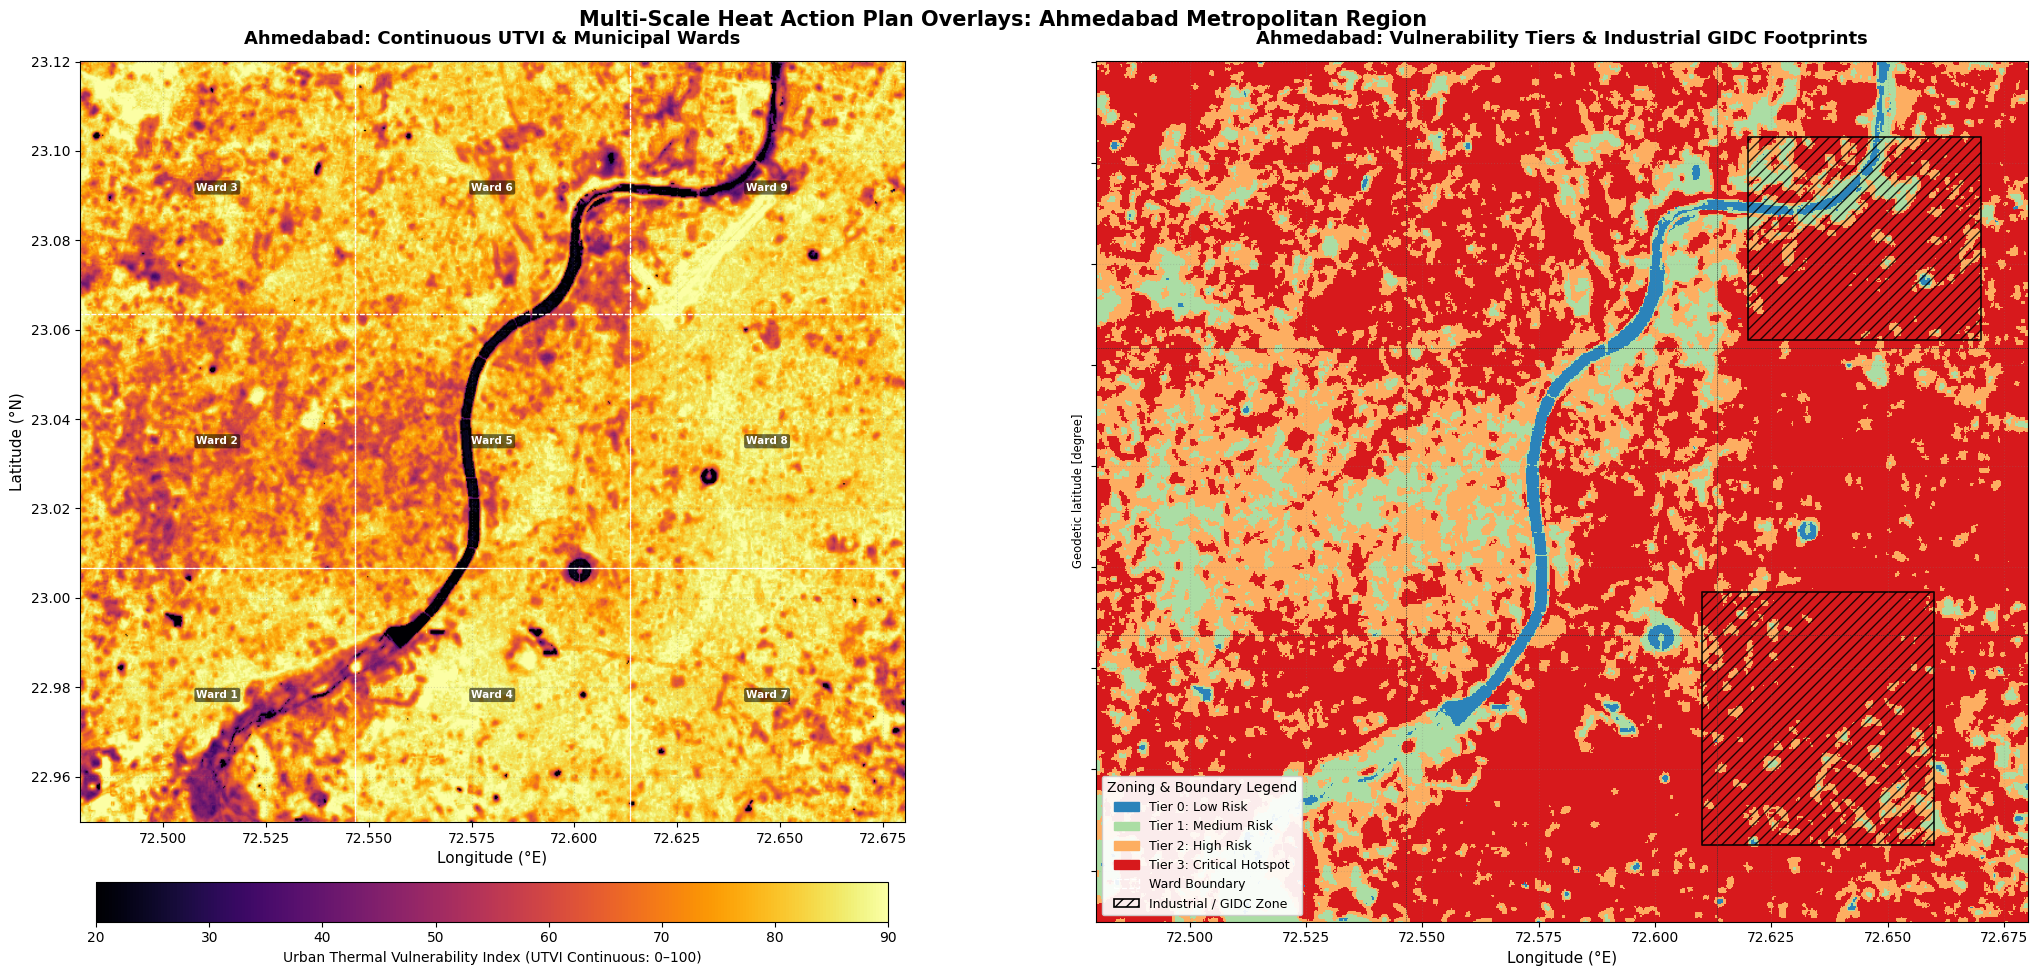


=== Top Municipal Wards by Thermal Vulnerability Exposure ===
ward_name  mean_utvi  max_utvi  critical_pct  critical_area_km2
   Ward 8  81.715860 97.681602     85.445469            40.0500
   Ward 7  80.283949 98.550568     76.482954            36.0198
   Ward 4  79.780552 98.533844     77.289405            36.3996
   Ward 3  76.910731 96.710281     57.821816            27.2313
   Ward 9  76.843363 97.863777     65.739184            30.9600
   Ward 6  74.978095 98.156578     57.548540            27.1026
   Ward 1  74.340339 98.201332     54.792845            25.8048
   Ward 5  71.613009 95.902199     39.548771            18.5373


In [ ]:
import os
import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import rasterio
from rasterio.plot import plotting_extent
from shapely.geometry import box

# -------------------------------------------------------------------------
# 1. File Paths
# -------------------------------------------------------------------------
GEOTIFF_PATH    = "/content/drive/MyDrive/UHI_Project/inferred_rasters/ahmedabad_summer_utvi_vulnerability_2band.tif"
WARDS_PATH      = "/content/drive/MyDrive/UHI_Project/vectors/ahmedabad_administrative_wards.geojson"
INDUSTRIAL_PATH = "/content/drive/MyDrive/UHI_Project/vectors/ahmedabad_industrial_zones.geojson"

if not os.path.exists(GEOTIFF_PATH):
    raise FileNotFoundError(f"GeoTIFF raster not found at: {GEOTIFF_PATH}")

# -------------------------------------------------------------------------
# 2. Read 2-Band Inferred Raster
# -------------------------------------------------------------------------
with rasterio.open(GEOTIFF_PATH) as src:
    extent        = plotting_extent(src)  # [minx, maxx, miny, maxy]
    raster_crs    = src.crs
    raster_affine = src.transform
    band_score    = src.read(1)           # Band 1: Continuous UTVI [0 - 100]
    band_class    = src.read(2)           # Band 2: 4-Tier Class [0, 1, 2, 3]
    nodata_val    = src.nodata

score_masked = np.ma.masked_where((band_score == nodata_val) | np.isnan(band_score), band_score)
class_masked = np.ma.masked_where((band_class == nodata_val) | (band_class == 255) | np.isnan(band_class), band_class)

minx, maxx, miny, maxy = extent[0], extent[1], extent[2], extent[3]

# -------------------------------------------------------------------------
# 3. Load or Synthesize Vectors (Reprojected to Raster CRS)
# -------------------------------------------------------------------------
if os.path.exists(WARDS_PATH):
    gdf_wards = gpd.read_file(WARDS_PATH).to_crs(raster_crs)
else:
    print("Notice: Ward GeoJSON not found on Drive. Generating 3x3 synthetic ward grid.")
    x_steps = np.linspace(minx, maxx, 4)
    y_steps = np.linspace(miny, maxy, 4)
    ward_boxes = [box(x_steps[i], y_steps[j], x_steps[i+1], y_steps[j+1]) for i in range(3) for j in range(3)]
    ward_names = [f"Ward {idx+1}" for idx in range(9)]
    gdf_wards = gpd.GeoDataFrame({"ward_name": ward_names, "geometry": ward_boxes}, crs=raster_crs)

if os.path.exists(INDUSTRIAL_PATH):
    gdf_ind = gpd.read_file(INDUSTRIAL_PATH).to_crs(raster_crs)
else:
    print("Notice: Industrial GeoJSON not found on Drive. Creating GIDC cluster footprints.")
    cx, cy = (minx + maxx) / 2.0, (miny + maxy) / 2.0
    ind_polys = [
        box(cx + 0.03, cy - 0.07, cx + 0.08, cy - 0.02),
        box(cx + 0.04, cy + 0.03, cx + 0.09, cy + 0.07)
    ]
    gdf_ind = gpd.GeoDataFrame({"zone_name": ["Vatva Industrial Zone", "Naroda GIDC Area"], "geometry": ind_polys}, crs=raster_crs)

# Clip vectors using shapely.geometry.box
bbox_polygon = box(minx, miny, maxx, maxy)
gdf_wards = gpd.clip(gdf_wards, bbox_polygon)
gdf_ind = gpd.clip(gdf_ind, bbox_polygon)

# -------------------------------------------------------------------------
# 4. Side-by-Side Visualization
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(22, 10), sharex=True, sharey=True)

# Subplot 1: Continuous UTVI + Wards
im1 = axes[0].imshow(
    score_masked,
    extent=extent,
    cmap="inferno",
    vmin=20.0,
    vmax=90.0,
    interpolation="bilinear"
)
axes[0].set_title("Ahmedabad: Continuous UTVI & Municipal Wards", fontsize=13, weight="bold", pad=12)
axes[0].set_xlabel("Longitude (°E)", fontsize=11)
axes[0].set_ylabel("Latitude (°N)", fontsize=11)

gdf_wards.boundary.plot(ax=axes[0], color="#ffffff", linewidth=0.9, linestyle="--", alpha=0.9)

for _, row in gdf_wards.iterrows():
    pt = row.geometry.centroid
    label_txt = row.get("ward_name", row.get("WARD_NAME", ""))
    if label_txt:
        axes[0].annotate(
            text=str(label_txt),
            xy=(pt.x, pt.y),
            fontsize=7.5,
            weight="bold",
            color="#ffffff",
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="#000000", alpha=0.55, edgecolor="none")
        )

cbar1 = fig.colorbar(im1, ax=axes[0], orientation="horizontal", fraction=0.046, pad=0.07)
cbar1.set_label("Urban Thermal Vulnerability Index (UTVI Continuous: 0–100)", fontsize=10)

# Subplot 2: Categorical Risk Zones + Industrial Polygons
class_colors = ["#2b83ba", "#abdda4", "#fdae61", "#d7191c"]
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], ncolors=4)

im2 = axes[1].imshow(
    class_masked,
    extent=extent,
    cmap=class_cmap,
    norm=class_norm,
    interpolation="nearest"
)
axes[1].set_title("Ahmedabad: Vulnerability Tiers & Industrial GIDC Footprints", fontsize=13, weight="bold", pad=12)
axes[1].set_xlabel("Longitude (°E)", fontsize=11)

gdf_wards.boundary.plot(ax=axes[1], color="#333333", linewidth=0.6, linestyle=":", alpha=0.7)

gdf_ind.plot(
    ax=axes[1],
    facecolor="none",
    edgecolor="#000000",
    linewidth=1.3,
    hatch="///",
    alpha=0.85
)

tier_labels = ["Low Risk", "Medium Risk", "High Risk", "Critical Hotspot"]
raster_legend = [
    mpatches.Patch(color=color, label=f"Tier {idx}: {label}")
    for idx, (color, label) in enumerate(zip(class_colors, tier_labels))
]
vector_legend = [
    mpatches.Patch(facecolor="none", edgecolor="#ffffff", linestyle="--", linewidth=1.0, label="Ward Boundary"),
    mpatches.Patch(facecolor="none", edgecolor="#000000", hatch="///", linewidth=1.2, label="Industrial / GIDC Zone")
]

axes[1].legend(
    handles=raster_legend + vector_legend,
    loc="lower left",
    frameon=True,
    framealpha=0.92,
    fontsize=9,
    title="Zoning & Boundary Legend",
    title_fontsize=10
)

for ax in axes:
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.grid(True, linestyle=":", alpha=0.25, color="gray")

plt.suptitle("Multi-Scale Heat Action Plan Overlays: Ahmedabad Metropolitan Region", fontsize=15, weight="bold", y=0.97)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 5. Ward Zonal Metrics
# -------------------------------------------------------------------------
try:
    from rasterstats import zonal_stats

    ward_stats = zonal_stats(
        gdf_wards,
        score_masked.filled(np.nan),
        affine=raster_affine,
        nodata=np.nan,
        stats=["mean", "max", "count"]
    )
    gdf_wards["mean_utvi"] = [s["mean"] for s in ward_stats]
    gdf_wards["max_utvi"]  = [s["max"] for s in ward_stats]

    crit_binary = (class_masked == 3).astype(np.float32)
    crit_stats = zonal_stats(
        gdf_wards,
        crit_binary.filled(np.nan),
        affine=raster_affine,
        nodata=np.nan,
        stats=["sum", "count"]
    )
    gdf_wards["critical_area_km2"] = [(s["sum"] * 900.0) / 1e6 for s in crit_stats]
    gdf_wards["critical_pct"]      = [(s["sum"] / s["count"] * 100.0) if s["count"] > 0 else 0.0 for s in crit_stats]

    name_col = "ward_name" if "ward_name" in gdf_wards.columns else "WARD_NAME"
    ranking = gdf_wards[[name_col, "mean_utvi", "max_utvi", "critical_pct", "critical_area_km2"]].sort_values(
        by="mean_utvi", ascending=False
    )

    print("\n=== Top Municipal Wards by Thermal Vulnerability Exposure ===")
    print(ranking.head(8).to_string(index=False))

except ImportError:
    print("\nOptional: Install `rasterstats` (`!pip install rasterstats`) to calculate zonal summary tables.")

In [ ]:
"""
STEP 1 (Colab): export HELD-OUT cities from Google Earth Engine in EXACTLY the
same format as your training data (10 bands, 2022-2024 multi-year seasonal
median, same DOY windows, same QA mask, 30 m, EPSG:4326).

Training cities  : nagpur, mumbai, hyderabad, bengaluru, dehradun
Held-out (here)  : ahmedabad, jaipur, chennai, kolkata, pune  (edit freely)
"""
import math, ee

try:
    ee.Initialize(project='landsat89-509617')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='landsat89-509617')

# ---- new cities (0.3 x ~0.25 deg boxes, same size class as training AOIs) ----
new_cities = {
    "ahmedabad_arid_industrial": ee.Geometry.BBox(72.45, 22.85, 72.75, 23.15),
    "jaipur_semiarid":           ee.Geometry.BBox(75.65, 26.78, 75.95, 27.03),
    "chennai_coastal":           ee.Geometry.BBox(80.10, 12.95, 80.40, 13.20),
    "kolkata_delta":             ee.Geometry.BBox(88.20, 22.45, 88.50, 22.70),
    "pune_deccan":               ee.Geometry.BBox(73.70, 18.40, 74.00, 18.65),
}

# ---- identical to your multi-year training script ----------------------
seasonal_windows = {
    "summer":       {"start_doy": 91,  "end_doy": 166, "rep_doy": 128},
    "monsoon":      {"start_doy": 182, "end_doy": 258, "rep_doy": 220},
    "post_monsoon": {"start_doy": 274, "end_doy": 334, "rep_doy": 304},
    "winter":       {"start_doy": 349, "end_doy": 46,  "rep_doy": 15},
}
YEARS = [2022, 2023, 2024]

def prepare_landsat(image):
    qa = image.select('QA_PIXEL')
    bad = (qa.bitwiseAnd(1 << 1).neq(0).Or(qa.bitwiseAnd(1 << 3).neq(0))
             .Or(qa.bitwiseAnd(1 << 4).neq(0)).Or(qa.bitwiseAnd(1 << 5).neq(0)))
    clear_qa = bad.Not()
    optical = (image.select(['SR_B3', 'SR_B4', 'SR_B5', 'SR_B6'])
               .multiply(0.0000275).add(-0.2).rename(['Green', 'Red', 'NIR', 'SWIR1']))
    lst = (image.select('ST_B10').multiply(0.00341802).add(149.0)
           .subtract(273.15).rename('LST'))
    valid = clear_qa.And(image.select('ST_B10').mask())
    return (image.addBands(optical.updateMask(valid), overwrite=True)
                 .addBands(lst.updateMask(valid), overwrite=True)
                 .addBands(valid.toFloat().rename('Quality_Flag'), overwrite=True))

def build_collection(aoi, season_key, cfg):
    l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterBounds(aoi) \
           .filter(ee.Filter.calendarRange(YEARS[0], YEARS[-1], 'year'))
    l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterBounds(aoi) \
           .filter(ee.Filter.calendarRange(YEARS[0], YEARS[-1], 'year'))
    col = l8.merge(l9)
    if season_key == "winter":
        col = col.filter(ee.Filter.Or(
            ee.Filter.calendarRange(cfg["start_doy"], 366, 'day_of_year'),
            ee.Filter.calendarRange(1, cfg["end_doy"], 'day_of_year')))
    else:
        col = col.filter(ee.Filter.calendarRange(cfg["start_doy"], cfg["end_doy"], 'day_of_year'))
    return col

def generate_multiyear_stack(aoi, season_key, cfg):
    proc = build_collection(aoi, season_key, cfg).map(prepare_landsat)
    print(f"    {season_key}: {proc.size().getInfo()} Landsat images")
    q = proc.select('Quality_Flag')
    valid_cnt = q.sum().rename('Valid_Observation_Count').clip(aoi)
    obs_cnt   = q.count().rename('Observation_Count').clip(aoi)
    qscore    = valid_cnt.divide(obs_cnt.max(1)).rename('Quality_Score').clip(aoi)
    comp = proc.select(['LST', 'Green', 'Red', 'NIR', 'SWIR1']).median().clip(aoi)
    ndvi  = comp.normalizedDifference(['NIR', 'Red']).rename('NDVI')
    ndbi  = comp.normalizedDifference(['SWIR1', 'NIR']).rename('NDBI')
    mndwi = comp.normalizedDifference(['Green', 'SWIR1']).rename('MNDWI')
    elev  = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(aoi).rename('Elevation')
    d = cfg["rep_doy"]
    ds = ee.Image.constant(math.sin(2 * math.pi * d / 365.25)).toFloat().rename('doy_sin').clip(aoi)
    dc = ee.Image.constant(math.cos(2 * math.pi * d / 365.25)).toFloat().rename('doy_cos').clip(aoi)
    return (comp.select('LST').addBands(ndvi).addBands(ndbi).addBands(mndwi)
            .addBands(elev).addBands(ds).addBands(dc)
            .addBands(qscore).addBands(valid_cnt).addBands(obs_cnt).toFloat())

# ---- launch exports -----------------------------------------------------
FOLDER = 'EarthEngine_Exports_HeldOut'
tasks = {}
for city, aoi in new_cities.items():
    print(f"\n{city}")
    for sk, cfg in seasonal_windows.items():
        prefix = f"uhi_features_{city}_{sk}_multiyear_30m"
        t = ee.batch.Export.image.toDrive(
            image=generate_multiyear_stack(aoi, sk, cfg), description=f"HO_{city}_{sk}",
            folder=FOLDER, fileNamePrefix=prefix, scale=30, region=aoi,
            crs='EPSG:4326', maxPixels=1e9)
        t.start(); tasks[prefix] = t
        print(f"    submitted {prefix}")
print(f"\n{len(tasks)} tasks queued -> Drive folder '{FOLDER}'. Check https://code.earthengine.google.com/tasks")


ahmedabad_arid_industrial
    summer: 56 Landsat images
    submitted uhi_features_ahmedabad_arid_industrial_summer_multiyear_30m
    monsoon: 25 Landsat images
    submitted uhi_features_ahmedabad_arid_industrial_monsoon_multiyear_30m
    post_monsoon: 46 Landsat images
    submitted uhi_features_ahmedabad_arid_industrial_post_monsoon_multiyear_30m
    winter: 47 Landsat images
    submitted uhi_features_ahmedabad_arid_industrial_winter_multiyear_30m

jaipur_semiarid
    summer: 56 Landsat images
    submitted uhi_features_jaipur_semiarid_summer_multiyear_30m
    monsoon: 38 Landsat images
    submitted uhi_features_jaipur_semiarid_monsoon_multiyear_30m
    post_monsoon: 46 Landsat images
    submitted uhi_features_jaipur_semiarid_post_monsoon_multiyear_30m
    winter: 42 Landsat images
    submitted uhi_features_jaipur_semiarid_winter_multiyear_30m

chennai_coastal
    summer: 27 Landsat images
    submitted uhi_features_chennai_coastal_summer_multiyear_30m
    monsoon: 25 Landsat i

In [ ]:
"""
STEP 2 (Colab): evaluate the trained model on held-out city rasters.

"Real" label = EXACTLY your training label:
    UTVI = clip((LST - (mu - 2*sd)) / (4*sd) * 100, 0, 100)
with mu/sd computed over the valid pixels of that city x season scene.
Classes: <37.5 Low, <62.5 Medium, <78 High, else Critical.
"""
import os, re, glob, joblib, numpy as np, pandas as pd, rasterio
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter, label
from scipy.stats import spearmanr
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score,
                             f1_score, cohen_kappa_score, confusion_matrix, classification_report)

BUNDLE_PATH = "/content/drive/MyDrive/UHI_Project/models/spatial_uhi_score_pipeline.joblib"
DATA_DIR    = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_HeldOut"
OUT_DIR     = "/content/drive/MyDrive/UHI_Project/heldout_eval"
TRAIN_CITIES = ("nagpur", "mumbai", "hyderabad", "bengaluru", "dehradun")
os.makedirs(OUT_DIR, exist_ok=True)

bundle = joblib.load(BUNDLE_PATH)
model, scaler, FEATS = bundle["model"], bundle["scaler"], bundle["feature_names"]
T1, T2, T3 = (bundle["score_thresholds"][k] for k in ("low_upper", "medium_upper", "critical_lower"))
CLS = ["Low", "Medium", "High", "Critical"]

# ---- filters identical to your training preprocessing -------------------
def mean_filter(data, size):
    valid = np.isfinite(data); filled = np.where(valid, data, 0)
    s = uniform_filter(filled, size=size, mode="nearest")
    c = uniform_filter(valid.astype(float), size=size, mode="nearest")
    return np.divide(s, c, out=np.full_like(s, np.nan, dtype=float), where=c > 0)

def std_filter(data, size):
    valid = np.isfinite(data); filled = np.where(valid, data, 0)
    m = mean_filter(data, size)
    c = uniform_filter(valid.astype(float), size=size, mode="nearest")
    m2 = np.divide(uniform_filter(filled ** 2, size=size, mode="nearest"), c,
                   out=np.full_like(m, np.nan, dtype=float), where=c > 0)
    return np.sqrt(np.maximum(m2 - m ** 2, 0))

def classes(s):
    c = np.zeros(len(s), dtype=np.int8)
    c[(s >= T1) & (s < T2)] = 1; c[(s >= T2) & (s < T3)] = 2; c[s >= T3] = 3
    return c

def postprocess(score2d, cls2d, mndwi, valid):
    """Same steps as your inference script: water clamp, 3x3 modal smoothing, tiny-cluster pruning."""
    c = np.where(valid, cls2d, 0).astype(np.uint8)
    water = (mndwi > 0.0) & valid; c[water] = 0
    cnt = np.stack([uniform_filter((c == k).astype(np.float32), size=3, mode="reflect") * 9 for k in range(4)], -1)
    maj = np.argmax(cnt, -1).astype(np.uint8)
    agree = np.take_along_axis(cnt, c[:, :, None].clip(0, 3), -1).squeeze(-1)
    sp = valid & (agree < 3) & (~water); c[sp] = maj[sp]
    lab, n = label(c == 3, structure=np.ones((3, 3), int))
    if n:
        k = np.bincount(lab.ravel()); small = np.where((k < 10) & (k > 0))[0]
        c[np.isin(lab, small)] = 2
    return c

# ---- scene loading / labelling -----------------------------------------
def load_scene(path):
    with rasterio.open(path) as s:
        b = s.read().astype(np.float64); nod = s.nodata; prof = s.profile
    if nod is not None: b[b == nod] = np.nan
    LST, NDVI, NDBI, MNDWI, ELEV, DS, DC = b[:7]
    F = {"NDVI": NDVI, "NDBI": NDBI, "MNDWI": MNDWI, "Elevation": ELEV,
         "NDVI_mean_3x3": mean_filter(NDVI, 3), "NDBI_mean_5x5": mean_filter(NDBI, 5),
         "NDBI_std_3x3": std_filter(NDBI, 3), "NDVI_std_3x3": std_filter(NDVI, 3),
         "MNDWI_mean_3x3": mean_filter(MNDWI, 3), "doy_sin": DS, "doy_cos": DC}
    shape = LST.shape
    X = np.column_stack([F[f].ravel() for f in FEATS]); lst = LST.ravel()
    ok = np.isfinite(X).all(1) & np.isfinite(lst)
    ok &= (np.abs(X[:, FEATS.index("NDVI")]) <= 1) & (np.abs(X[:, FEATS.index("NDBI")]) <= 1)
    ok &= (np.abs(X[:, FEATS.index("MNDWI")]) <= 1)
    e = X[:, FEATS.index("Elevation")]; ok &= (e >= -200) & (e <= 9000) & (lst >= -10) & (lst <= 70)
    return X, lst, ok, shape, prof

def true_score(lst):
    mu, sd = lst.mean(), lst.std(ddof=1)            # polars .std() is ddof=1
    return np.clip((lst - (mu - 2 * sd)) / (4 * sd) * 100, 0, 100)

def metrics(ts, ps, tc, pc):
    top = lambda a: a >= np.quantile(a, 0.90)
    crit_t, crit_p = tc == 3, pc == 3
    return dict(
        R2=r2_score(ts, ps), RMSE=np.sqrt(mean_squared_error(ts, ps)), MAE=mean_absolute_error(ts, ps),
        Pearson=np.corrcoef(ts, ps)[0, 1], Spearman=spearmanr(ts, ps)[0],
        Bias=float(np.mean(ps - ts)), StdRatio=float(np.std(ps) / np.std(ts)),
        Acc=accuracy_score(tc, pc), MacroF1=f1_score(tc, pc, average="macro"),
        QWK=cohen_kappa_score(tc, pc, weights="quadratic"), Within1=float(np.mean(np.abs(tc.astype(int) - pc) <= 1)),
        Top10_overlap=float((top(ts) & top(ps)).sum() / top(ts).sum()),
        Crit_precision=float((crit_t & crit_p).sum() / max(crit_p.sum(), 1)),
        Crit_recall=float((crit_t & crit_p).sum() / max(crit_t.sum(), 1)))

rows, tile_rows = [], []
files = sorted(glob.glob(os.path.join(DATA_DIR, "uhi_features_*_multiyear_30m.tif")))
print(f"{len(files)} scenes found")
for path in files:
    m = re.match(r"uhi_features_(.+?)_(summer|monsoon|post_monsoon|winter)_multiyear_30m", os.path.basename(path))
    city, season = m.group(1), m.group(2)
    if city.startswith(TRAIN_CITIES): print(f"  WARNING: {city} looks like a TRAINING city - not a held-out test")
    X, lst, ok, shape, prof = load_scene(path)
    if ok.sum() < 5000: print(f"skip {city}/{season}: only {ok.sum()} valid px"); continue
    ts = true_score(lst[ok]); tc = classes(ts)
    ps = np.clip(model.predict(scaler.transform(X[ok])), 0, 100); pc = classes(ps)
    mt = metrics(ts, ps, tc, pc)

    # post-processed classes (as in deployment) scored on the same pixels
    g = lambda v, fill=np.nan: np.full(ok.size, fill, np.float32);
    cls_grid = np.zeros(ok.size, np.uint8); cls_grid[ok] = pc
    mndwi = X[:, FEATS.index("MNDWI")].reshape(shape)
    pp = postprocess(None, cls_grid.reshape(shape), mndwi, ok.reshape(shape)).ravel()[ok]
    mt_pp = dict(PP_Acc=accuracy_score(tc, pp), PP_MacroF1=f1_score(tc, pp, average="macro"),
                 PP_QWK=cohen_kappa_score(tc, pp, weights="quadratic"))
    rows.append(dict(city=city, season=season, n=int(ok.sum()), **mt, **mt_pp,
                     # simple spectral baselines (no ML): rank agreement with true LST score
                     Spearman_negNDVI=spearmanr(ts, -X[ok, FEATS.index("NDVI")])[0],
                     Spearman_NDBI=spearmanr(ts, X[ok, FEATS.index("NDBI")])[0]))
    print(f"\n=== {city} / {season}  (n={ok.sum():,}) ===")
    print(f"R2={mt['R2']:.3f} RMSE={mt['RMSE']:.1f} MAE={mt['MAE']:.1f} Spearman={mt['Spearman']:.3f} "
          f"| Acc={mt['Acc']:.3f} F1={mt['MacroF1']:.3f} QWK={mt['QWK']:.3f} Within1={mt['Within1']:.3f}")
    print(confusion_matrix(tc, pc, labels=[0, 1, 2, 3]))

    # 3x3 spatial tiles: is skill consistent across the city?
    H, W = shape; rr, cc = np.divmod(np.flatnonzero(ok), W)
    ti = np.minimum(rr * 3 // H, 2) * 3 + np.minimum(cc * 3 // W, 2)
    for t in range(9):
        k = ti == t
        if k.sum() > 2000:
            tile_rows.append(dict(city=city, season=season, tile=t, n=int(k.sum()),
                                  R2=r2_score(ts[k], ps[k]), Spearman=spearmanr(ts[k], ps[k])[0]))
    # maps
    full = lambda v: np.where(ok.reshape(shape), np.nan, np.nan)
    tg = np.full(ok.size, np.nan); tg[ok] = ts; pg = np.full(ok.size, np.nan); pg[ok] = ps
    tg, pg = tg.reshape(shape), pg.reshape(shape)
    fig, ax = plt.subplots(1, 4, figsize=(22, 5))
    for a, grid, t, cm, lim in [(ax[0], tg, "Real UTVI (from LST)", "inferno", (0, 100)),
                                (ax[1], pg, "Predicted UTVI", "inferno", (0, 100)),
                                (ax[2], pg - tg, "Error (pred-real)", "RdBu_r", (-40, 40))]:
        im = a.imshow(grid, cmap=cm, vmin=lim[0], vmax=lim[1]); a.set_title(t); a.axis("off"); plt.colorbar(im, ax=a, fraction=.046)
    i = np.random.default_rng(0).choice(len(ts), min(20000, len(ts)), replace=False)
    ax[3].scatter(ts[i], ps[i], s=2, alpha=.25); ax[3].plot([0, 100], [0, 100], "r--")
    ax[3].set_xlabel("Real"); ax[3].set_ylabel("Predicted"); ax[3].set_title(f"R²={mt['R2']:.2f}  ρ={mt['Spearman']:.2f}")
    fig.suptitle(f"{city} - {season}"); plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"eval_{city}_{season}.png"), dpi=110); plt.close(fig)

res = pd.DataFrame(rows); tiles = pd.DataFrame(tile_rows)
res.to_csv(os.path.join(OUT_DIR, "scene_metrics.csv"), index=False)
tiles.to_csv(os.path.join(OUT_DIR, "tile_metrics.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
key = ["R2", "RMSE", "MAE", "Spearman", "Bias", "StdRatio", "Acc", "MacroF1", "QWK", "Within1", "Top10_overlap", "PP_Acc", "PP_MacroF1"]
print("\n\n######## PER CITY (mean over seasons) ########")
print(res.groupby("city")[key].mean().round(3))
print("\n######## PER SEASON (mean over cities) ########")
print(res.groupby("season")[key].mean().round(3))
print("\n######## OVERALL ########")
print(res[key].agg(["mean", "std", "min", "max"]).round(3).T)
print("\nSpectral-only baselines (Spearman, mean):",
      res[["Spearman", "Spearman_negNDVI", "Spearman_NDBI"]].mean().round(3).to_dict())
if len(tiles):
    print("\nSpatial consistency (per 3x3 tile): median Spearman "
          f"{tiles.Spearman.median():.3f}, worst tile {tiles.Spearman.min():.3f}")

20 scenes found

=== ahmedabad_arid_industrial / monsoon  (n=1,240,996) ===
R2=0.183 RMSE=21.2 MAE=17.7 Spearman=0.656 | Acc=0.366 F1=0.367 QWK=0.478 Within1=0.891
[[ 78402 247767  56845   4263]
 [ 10883 206364 236791  51003]
 [  1076  45459  93555  49563]
 [   272  22255  61189  75309]]

=== ahmedabad_arid_industrial / post_monsoon  (n=1,240,996) ===
R2=-0.657 RMSE=29.8 MAE=26.2 Spearman=0.741 | Acc=0.187 F1=0.169 QWK=0.306 Within1=0.653
[[ 10229 160192 141848  29449]
 [     3  42666 256838 258819]
 [     0    941  39291 151779]
 [     0     42   8812 140087]]

=== ahmedabad_arid_industrial / summer  (n=1,240,996) ===
R2=-0.841 RMSE=31.3 MAE=27.0 Spearman=0.685 | Acc=0.153 F1=0.122 QWK=0.245 Within1=0.590
[[  4893 112407 150051  55956]
 [     0   7706 217524 303395]
 [     0     42  30642 205657]
 [     0      8   5662 147053]]

=== ahmedabad_arid_industrial / winter  (n=1,240,996) ===
R2=-0.499 RMSE=29.2 MAE=24.4 Spearman=0.608 | Acc=0.261 F1=0.235 QWK=0.324 Within1=0.711
[[ 12944 19

accuracy is low but correlation is high, post-processing will be added for more accurate classification and new city will be added into retraining of model